# Demanda de Inventario de Grupo Bimbo (Descripcion)

## 1. Tiempo y logística

* **`Semana` (Número de semana):** Representa el período de tiempo de la transacción. La semana operativa de Grupo Bimbo comprende desde el jueves hasta el miércoles.
* **`Agencia_ID` (Identificador de agencia):** Identifica el centro de distribución físico donde se cargan los camiones de reparto con productos frescos.
* **`Canal_ID` (Identificador de canal de ventas):** Identifica la categoría del cliente, como pequeñas tiendas de barrio (*tienditas*), grandes supermercados y tiendas de conveniencia.
* **`Ruta_SAK` (Identificador de ruta):** Identifica la ruta geográfica específica que recorre un camión de reparto. Una misma agencia puede tener varias rutas de distribución.

## 2. Entidades

* **`Cliente_ID` y `NombreCliente` (Identificador y nombre del cliente):** Identifican la tienda específica que recibe la entrega, como «Abarrotes La Lupita» o una sucursal de Walmart.
* **`Producto_ID` y `NombreProducto` (Identificador y nombre del producto):** Identifican el producto específico que se entrega, incluyendo su marca, nombre y peso. Por ejemplo, «Pan Blanco Bimbo 680 g».

## 3. Flujo de transacciones

* **`Venta_uni_hoy` (Unidades entregadas esta semana):** Número de unidades de producto que el conductor entrega físicamente a la tienda durante la semana actual.
* **`Venta_hoy` (Ingresos por ventas de esta semana):** Ingresos brutos, expresados en pesos mexicanos, correspondientes a las unidades entregadas a la tienda.
* **`Dev_uni_proxima` (Unidades devueltas la próxima semana):** Número de unidades de la entrega actual que no se vendieron antes de caducar. El conductor recoge estos productos vencidos, conocidos como *merma por caducidad*, durante la entrega de la semana siguiente.
* **`Dev_proxima` (Valor de las devoluciones de la próxima semana):** Valor monetario, expresado en pesos mexicanos, reembolsado o acreditado a la tienda por las unidades devueltas debido a su caducidad.

## 4. Variable objetivo: `Demanda_uni_equil`

La **demanda ajustada** es la variable objetivo que se busca predecir. Representa una estimación de la demanda del consumidor final: la cantidad de unidades de producto que los consumidores realmente compraron, en lugar de limitarse a contar las unidades entregadas a una tienda.

# Mapa del cuaderno

En este proyecto trabajamos con **dos versiones del dataset**. Para que no se mezclen, cada parte indica cuál usa:

| Parte | Qué se hace | Dataset usado |
|---|---|---|
| 1. Carga de datos | Leer `train.csv`, `producto_tabla` y `cliente_tabla` | Completo (74M filas) |
| 2. Muestra del 3% | Sacar una muestra y comprobar que representa al completo | Completo → Muestra (2.2M) |
| 3. Análisis exploratorio (EDA) | Correlaciones, histogramas, concentración de la demanda | Ambos (se comparan) |
| 4. Feature Engineering descriptivo | Precio, piezas, gramos, marca, familia, tipo de tienda | Muestra |
| 5. Secuencias de tiempo | Series Agencia × Producto y variables temporales | Completo (agregado) |
| 6. Modelos y finetuning | LSTM, ventana de 1 vs 3 semanas, ajuste de hiperparámetros | Completo (agregado) |
| 7. Función de predicción | Predecir la demanda de un producto en una semana | Completo (agregado) |

**¿Por qué dos datasets?**
* La **muestra** existe por memoria: con los 74M de filas la RAM llega al 92% y las gráficas tardan unos 15 minutos. Para explorar y para crear variables descriptivas (cruces con nombres de clientes y productos), el 3% alcanza porque conserva las proporciones.
* El **modelo usa el completo**, pero agregado por Agencia × Producto × Semana. Así los 74M de filas se reducen a unas 54 mil series, que caben sin problema. La muestra no sirve para el modelo: al elegir filas al azar se rompen las series (ver Parte 5).

**Para volver a correr solo el modelo:** basta ejecutar la Parte 1 y después las Partes 5, 6 y 7.

# Parte 1. Carga de datos

**Dataset usado: completo (74M filas).**

In [4]:
import matplotlib.pyplot as plt
import pandas as pd 
import numpy as np
import copy
import os
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [7]:
print(os.getcwd())

C:\Users\alexi\OneDrive\Escritorio\Personal\Proyecto_DL\backend\ai


In [ ]:
dtypes = { #bajar la memoria de los datos para mejorar la lectura de datos 
    'Semana': 'int8',
    'Agencia_ID': 'int16',
    'Canal_ID': 'int8',
    'Ruta_SAK': 'int32',
    'Cliente_ID': 'int32',
    'Producto_ID': 'int32',
    'Venta_uni_hoy': 'int32',
    'Venta_hoy': 'float32',
    'Dev_uni_proxima': 'int32',
    'Dev_proxima': 'float32',
    'Demanda_uni_equil': 'int32'
}

productos = pd.read_csv("../data/raw/producto_tabla.csv") 
clientes = pd.read_csv("../data/raw/cliente_tabla.csv")

df = pd.read_csv("../data/raw/train.csv", dtype=dtypes) #nrows=3_000_000) #May change | skiprows=range(1, 50_000_001), , nrows=6_000_000

In [4]:
#Presentar: Cuantas valores hay en cada semana antes de cambiarlo:
listita = df['Semana'].unique()
for i in range(2,11):
    print( f" Semana {i} tiene: {(df['Semana'] == i).sum()} registros")
'''
Presentar: En base a esto se puede ver que todos tienen mas de 10 millones
de registros.
'''

 Semana 2 tiene: 0 registros
 Semana 3 tiene: 11165207 registros
 Semana 4 tiene: 11009593 registros
 Semana 5 tiene: 10615397 registros
 Semana 6 tiene: 10191837 registros
 Semana 7 tiene: 10382849 registros
 Semana 8 tiene: 10406868 registros
 Semana 9 tiene: 10408713 registros
 Semana 10 tiene: 0 registros


'\nPresentar: En base a esto se puede ver que todos tienen mas de 10 millones\nde registros.\n'

## Registros en dataset principal


Primeros y ultimos 5 registros del dataset de **train**:

In [19]:
df.head()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
0,3,1110,7,3301,15766,1212,3,25.139999,0,0.0,3
1,3,1110,7,3301,15766,1216,4,33.520000,0,0.0,4
2,3,1110,7,3301,15766,1238,4,39.320000,0,0.0,4
3,3,1110,7,3301,15766,1240,4,33.520000,0,0.0,4
4,3,1110,7,3301,15766,1242,3,22.920000,0,0.0,3


In [20]:
df.tail()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
74180459,9,25759,1,5517,4528866,32873,4,27.760000,0,0.000000,4
74180460,9,25759,1,5517,4528866,34226,4,37.040001,0,0.000000,4
74180461,9,25759,1,5517,4528866,45112,4,51.000000,0,0.000000,4
74180462,9,25759,1,5517,4547943,40217,3,26.940001,3,26.940001,0
74180463,9,25759,1,5517,4708097,43159,1,10.400000,0,0.000000,1


In [21]:
df.describe()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
count,7.418046e+07,7.418046e+07,7.418046e+07,7.418046e+07,7.418046e+07,7.418046e+07,7.418046e+07,7.418046e+07,7.418046e+07,7.418046e+07,7.418046e+07
mean,5.950021e+00,2.536509e+03,1.383181e+00,2.114855e+03,1.802119e+06,2.084081e+04,7.310163e+00,6.854449e+01,1.302577e-01,1.243248e+00,7.224564e+00
std,2.013175e+00,4.075124e+03,1.463266e+00,1.487744e+03,2.349577e+06,1.866392e+04,2.196734e+01,3.357969e+02,2.932320e+01,3.907285e+01,2.177119e+01
min,3.000000e+00,1.110000e+03,1.000000e+00,1.000000e+00,2.600000e+01,4.100000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,4.000000e+00,1.312000e+03,1.000000e+00,1.161000e+03,3.567670e+05,1.242000e+03,2.000000e+00,1.676000e+01,0.000000e+00,0.000000e+00,2.000000e+00
50%,6.000000e+00,1.613000e+03,1.000000e+00,1.286000e+03,1.193385e+06,3.054900e+04,3.000000e+00,3.000000e+01,0.000000e+00,0.000000e+00,3.000000e+00
75%,8.000000e+00,2.036000e+03,1.000000e+00,2.802000e+03,2.371091e+06,3.742600e+04,7.000000e+00,5.610000e+01,0.000000e+00,0.000000e+00,6.000000e+00
max,9.000000e+00,2.575900e+04,1.100000e+01,9.991000e+03,2.015152e+09,4.999700e+04,7.200000e+03,6.473600e+05,2.500000e+05,1.307600e+05,5.000000e+03


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74180464 entries, 0 to 74180463
Data columns (total 11 columns):
 #   Column             Dtype  
---  ------             -----  
 0   Semana             int8   
 1   Agencia_ID         int16  
 2   Canal_ID           int8   
 3   Ruta_SAK           int32  
 4   Cliente_ID         int32  
 5   Producto_ID        int32  
 6   Venta_uni_hoy      int32  
 7   Venta_hoy          float32
 8   Dev_uni_proxima    int32  
 9   Dev_proxima        float32
 10  Demanda_uni_equil  int32  
dtypes: float32(2), int16(1), int32(6), int8(2)
memory usage: 2.5 GB


## Registros en producto_tabla y cliente_tabla


Primeros 5 registros del dataset de **producto_tabla**:

In [27]:
#df.to_csv("train_sample_2.csv", index= False)
productos.head()

,Producto_ID,NombreProducto
0,0,NO IDENTIFICADO 0
1,9,Capuccino Moka 750g NES 9
2,41,Bimbollos Ext sAjonjoli 6p 480g BIM 41
3,53,Burritos Sincro 170g CU LON 53
4,72,Div Tira Mini Doradita 4p 45g TR 72



Primeros 5 registros del dataset de **cliente_tabla**:

In [19]:
clientes.head()

,Cliente_ID,NombreCliente
0,0,SIN NOMBRE
1,1,OXXO XINANTECATL
2,2,SIN NOMBRE
3,3,EL MORENO
4,4,SDN SER DE ALIM CUERPO SA CIA DE INT


## Dimensiones


Se observan 74_180_464 registros/observaciones en el dataset de entrenamiento. De estos, 880_604 ids de clientes y 1_799 ids de productos son valores unicos 

In [28]:
trainCliente = df['Cliente_ID'].nunique()
trainProducto = df['Producto_ID'].nunique()
print(f"Numero de valores unicos Cliente_ID en train: {trainCliente}") 
print(f"Numero de valores unicos Producto_ID en train: {trainProducto}")
print(df.shape[0])

Numero de valores unicos Cliente_ID en train: 880604
Numero de valores unicos Producto_ID en train: 1799
74180464


In [30]:
#productosNombre = productos['NombreProducto']
print(f"Duplicados en productos: {productos.duplicated(keep=False).sum()}")
#clientesNombre = clientes['NombreCliente']
print(f"Duplicados en Clientes: {clientes.duplicated(keep=False).sum()}")
#nombresDuplicados = clientesNombre.duplicated(keep=False).sum()
# Revision por ID (no por fila completa): si hay IDs repetidos el merge duplicaria filas
print(f"Producto_ID repetidos en productos: {productos['Producto_ID'].duplicated().sum()}")
print(f"Cliente_ID repetidos en clientes: {clientes['Cliente_ID'].duplicated().sum()}")

Duplicados en productos: 0
Duplicados en Clientes: 0
Producto_ID repetidos en productos: 0
Cliente_ID repetidos en clientes: 4862


# Parte 2. Muestra del 3%

**Dataset usado: completo → muestra (`final_df`).**

Primero se pensó sacar 300,000 registros por semana (ver el comentario de la siguiente celda). Al final se leyó `train.csv` en bloques de 1 millón de filas y de cada bloque se tomó el **3% al azar**. Así cada semana conserva su proporción real de registros.

In [5]:
'''
Presentar:Podemos ver que tenemos 74_180_464 registros 
para manejar el dataset de manera rapida, se dedide
sacar 300_000 registros por semanana, como vimos antes,
cada semana tiene 10 millones
de registros, entonces
podemos sacar 30_000 productos de cada muestra de 1_000_000

'''
print(df.shape)

(74180464, 11)


In [57]:
#Realizar una lista de dataframes. La lista contiene 74 objetos 
#de tipo DataFrame, cada uno con 30.000 registros y el mismo conjunto de columnas.
#A excepccion de la lista final (Ver mas abajo)
listaTemp = [] 
for chunk in pd.read_csv("../data/raw/train.csv", dtype = dtypes, chunksize=1_000_000):
    sample_chunk = chunk.sample(frac=0.03, random_state=42)
    listaTemp.append(sample_chunk)

In [58]:
'''
Presentar: Entonces ahora se tiene una lista con 74 dataframes,
el ultimo solo tiene 5414
'''
print(f"{listaTemp[0].shape[0]} | {listaTemp[10].shape[0]} | {listaTemp[74].shape[0]}  ") 

30000 | 30000 | 5414  


In [10]:
listaTemp[0].head()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
987231,3,1130,1,1009,1046574,1146,1,21.389999,0,0.0,1
79954,3,1112,1,1010,327766,2233,5,99.699997,0,0.0,5
567130,3,1121,1,1624,197555,31298,3,26.670000,0,0.0,3
500891,3,1120,1,2118,386617,36748,13,149.889999,0,0.0,13
55399,3,1111,1,1633,67057,303,6,27.240000,0,0.0,6


In [59]:
#Lo ponemos dentro de una lista (va sumando al final)
sample_entero = pd.concat(listaTemp, ignore_index=True)
sample_entero.shape[0]

2225414

In [60]:
#finalmente juntamos todo en final_df. Ya no se limita a 300_000 por semana,
#asi cada semana conserva su proporcion real de registros (~3% de cada una)
final_df = sample_entero.reset_index(drop=True)

## Comprobación: ¿la muestra se parece al dataset completo?

Comparamos qué porcentaje de registros tiene cada una de las 15 agencias principales en el completo y en la muestra. Si los porcentajes son casi iguales, la muestra es representativa.

In [61]:
'''
Comparacion del dataset gigante con el nuestra 
'''
# 1. Contar la distribución REAL
# Usamos int16 para optimizar la memoria al máximo al leer solo esta columna
distribucion_real = pd.Series(dtype='float32')
distribucion_real = distribucion_real.add(df['Agencia_ID'].value_counts(), fill_value=0)

In [62]:
print(distribucion_real)

Agencia_ID
1110      55275.0
1111     449195.0
1112     354849.0
1113     204224.0
1114      48028.0
           ...   
24049    106285.0
24539     95434.0
24669    133394.0
25699     71396.0
25759    214801.0
Length: 552, dtype: float64


In [63]:
# 2. Calcular los porcentajes (frecuencia relativa) para hacer una comparacion justa
# Nos enfocamos en las 15 agencias principales
top_15_real = (distribucion_real.nlargest(15) / distribucion_real.sum()) * 100
top_15_muestra = (final_df['Agencia_ID'].value_counts().nlargest(15) / len(final_df)) * 100
print(f"Esto equivale al {round(top_15_real.sum(), 2)} de la data real y al {round(top_15_muestra.sum(),2)} de la muestra")

Esto equivale al 12.36 de la data real y al 12.35 de la muestra


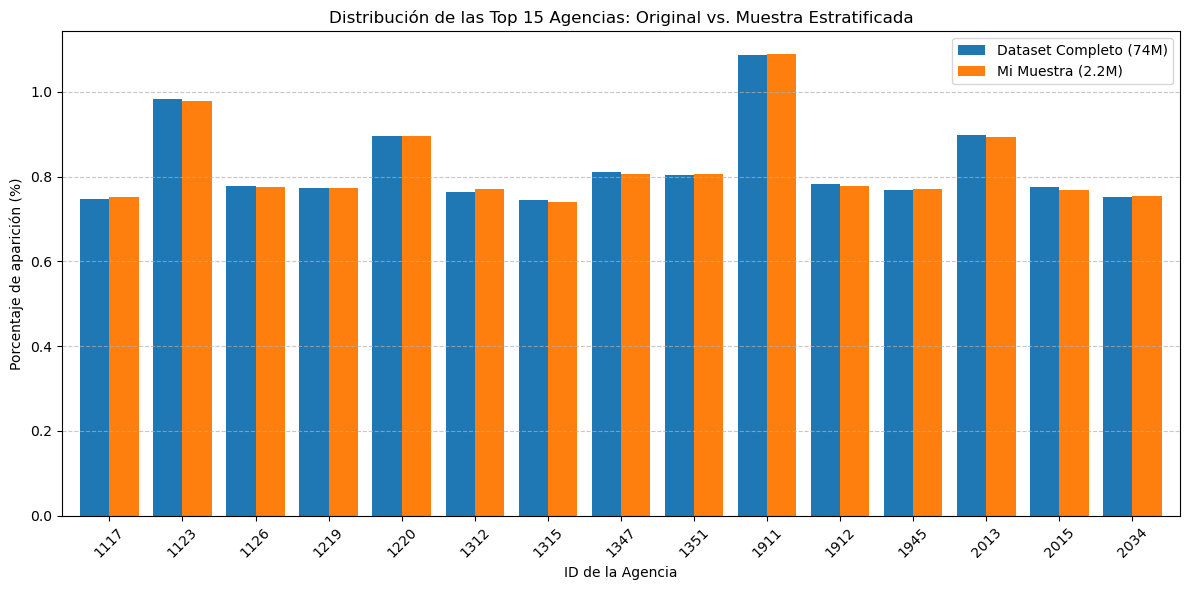

In [64]:

# 3. Alinear ambos resultados en una sola tabla
comparacion = pd.DataFrame({
    'Dataset Completo (74M)': top_15_real,
    'Mi Muestra (2.2M)': top_15_muestra
}).fillna(0)

# 4. Graficar la evidencia
comparacion.plot(kind='bar', figsize=(12, 6), width=0.8)
plt.title('Distribución de las Top 15 Agencias: Original vs. Muestra Estratificada')
plt.ylabel('Porcentaje de aparición (%)')
plt.xlabel('ID de la Agencia')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


## Registros en dataset de muestra

In [17]:
#Recuerda, final_df es el dataset de muestra final con el que nos quedamos, shi? 
listita = final_df['Semana'].unique()
for i in range(2,11):
    print( f" Semana {i} tiene: {(final_df['Semana'] == i).sum()} registros")

 Semana 2 tiene: 0 registros
 Semana 3 tiene: 335013 registros
 Semana 4 tiene: 330289 registros
 Semana 5 tiene: 318402 registros
 Semana 6 tiene: 305750 registros
 Semana 7 tiene: 311569 registros
 Semana 8 tiene: 312130 registros
 Semana 9 tiene: 312261 registros
 Semana 10 tiene: 0 registros


In [18]:
#Los 10 productos mas vendidos del dataset de muestra
listaCount = final_df['Producto_ID'].value_counts()
print(listaCount.head(10))

Producto_ID
1240     63956
1242     61503
2233     59321
1250     55964
1284     49888
1146     44701
1232     44369
1278     42035
41938    40740
1109     40649
Name: count, dtype: int64



Se observan 2_225_414 registros/observaciones en la muestra. De estos, 613_816 ids de clientes y 1_425 ids de productos son valores unicos 

In [29]:
muestraCliente = final_df['Cliente_ID'].nunique()
muestraProducto = final_df['Producto_ID'].nunique()
print(f"Numero de valores unicos Cliente_ID en la muestra: {muestraCliente}") 
print(f"Numero de valores unicos Producto_ID en la muestra: {muestraProducto}")
print(final_df.shape[0])
muestraPorcentaje= round((final_df.shape[0]/df.shape[0])*100)
muestraPorcentajeCliente= round((muestraCliente/trainCliente)*100, 2)
muestraPorcentajeProducto = round((muestraProducto /trainProducto)*100, 2)
print(f"Entonces tenemos el {muestraPorcentaje}% del total de datos y esta muestra tiene el \n{muestraPorcentajeCliente}% de todos los clientes y el {muestraPorcentajeProducto}% de todos los productos")

Numero de valores unicos Cliente_ID en la muestra: 613816
Numero de valores unicos Producto_ID en la muestra: 1425
2225414
Entonces tenemos el 3% del total de datos y esta muestra tiene el 
69.7% de todos los clientes y el 79.21% de todos los productos



Primeros y ultimos 5 registros del dataset de **muestra**:

In [23]:
final_df.head()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
0,3,1130,1,1009,1046574,1146,1,21.389999,0,0.0,1
1,3,1112,1,1010,327766,2233,5,99.699997,0,0.0,5
2,3,1121,1,1624,197555,31298,3,26.670000,0,0.0,3
3,3,1120,1,2118,386617,36748,13,149.889999,0,0.0,13
4,3,1111,1,1633,67057,303,6,27.240000,0,0.0,6


In [24]:
final_df.tail()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
2225409,9,25699,1,6502,836288,32873,5,34.700001,0,0.0,5
2225410,9,24669,1,1052,185455,46876,12,97.320000,0,0.0,12
2225411,9,23899,1,1244,442794,1284,5,15.100000,0,0.0,5
2225412,9,23719,1,1279,509072,1242,5,38.200001,0,0.0,5
2225413,9,24049,1,2801,2399569,35307,1,6.250000,0,0.0,1


In [25]:
final_df.describe()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil
count,2.225414e+06,2.225414e+06,2.225414e+06,2.225414e+06,2.225414e+06,2.225414e+06,2.225414e+06,2.225414e+06,2.225414e+06,2.225414e+06,2.225414e+06
mean,5.949939e+00,2.535838e+03,1.382274e+00,2.114214e+03,1.801207e+06,2.082235e+04,7.307996e+00,6.845585e+01,1.271786e-01,1.225802e+00,7.223236e+00
std,2.013199e+00,4.073791e+03,1.459833e+00,1.487018e+03,1.840595e+06,1.865876e+04,2.218305e+01,3.031636e+02,3.955327e+00,3.382110e+01,2.200183e+01
min,3.000000e+00,1.110000e+03,1.000000e+00,1.000000e+00,2.600000e+01,4.100000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,4.000000e+00,1.312000e+03,1.000000e+00,1.161000e+03,3.567562e+05,1.242000e+03,2.000000e+00,1.676000e+01,0.000000e+00,0.000000e+00,2.000000e+00
50%,6.000000e+00,1.613000e+03,1.000000e+00,1.286000e+03,1.192923e+06,3.054800e+04,3.000000e+00,3.000000e+01,0.000000e+00,0.000000e+00,3.000000e+00
75%,8.000000e+00,2.036000e+03,1.000000e+00,2.802000e+03,2.370566e+06,3.736100e+04,7.000000e+00,5.610000e+01,0.000000e+00,0.000000e+00,6.000000e+00
max,9.000000e+00,2.575900e+04,1.100000e+01,9.965000e+03,1.169326e+07,4.999600e+04,4.775000e+03,7.781682e+04,4.104000e+03,3.939840e+04,4.775000e+03


In [26]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225414 entries, 0 to 2225413
Data columns (total 11 columns):
 #   Column             Dtype  
---  ------             -----  
 0   Semana             int8   
 1   Agencia_ID         int16  
 2   Canal_ID           int8   
 3   Ruta_SAK           int32  
 4   Cliente_ID         int32  
 5   Producto_ID        int32  
 6   Venta_uni_hoy      int32  
 7   Venta_hoy          float32
 8   Dev_uni_proxima    int32  
 9   Dev_proxima        float32
 10  Demanda_uni_equil  int32  
dtypes: float32(2), int16(1), int32(6), int8(2)
memory usage: 76.4 MB


# Parte 3. Análisis exploratorio (EDA)

**Dataset usado: ambos.** Varias gráficas se hacen dos veces, una con el completo y otra con la muestra, para mostrar que dan el mismo resultado.

## Variables Numericas, Nominales


Columnas del dataset y clasificación de las variables:

In [35]:
df.columns

Index(['Semana', 'Agencia_ID', 'Canal_ID', 'Ruta_SAK', 'Cliente_ID',
       'Producto_ID', 'Venta_uni_hoy', 'Venta_hoy', 'Dev_uni_proxima',
       'Dev_proxima', 'Demanda_uni_equil'],
      dtype='object')

In [34]:
#Variables categoricas:
varCatNominal = ['Semana', 'Agencia_ID', 'Canal_ID', 'Ruta_SAK']
# Cliente_ID y Producto_ID tambien son categoricas nominales, 
#pero por la cantidad de datos no se procesaran, se usaran otros metodos.

#Variables Numericas:
varNumericas = ["Venta_uni_hoy", "Venta_hoy","Dev_uni_proxima", "Dev_proxima", "Demanda_uni_equil"]

## Matriz de correlación: completo vs. muestra

`Demanda_uni_equil` tiene correlación ~1.00 con `Venta_uni_hoy`, porque la demanda es casi la venta menos la devolución. Por eso **las ventas y devoluciones de la misma semana no se pueden usar para predecir la demanda de esa semana** (sería fuga de información).

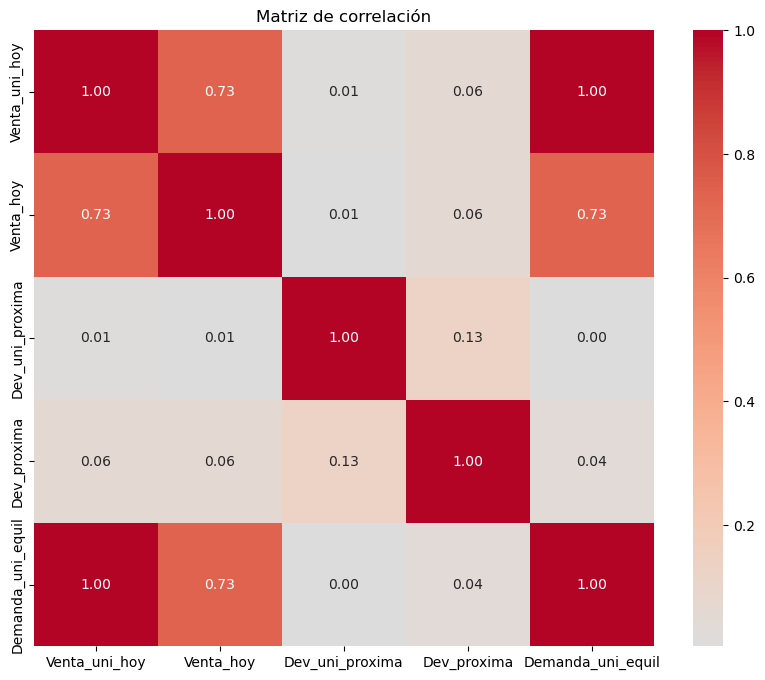

In [36]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[varNumericas].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.show()
#Grafica con los 70 millones de datos

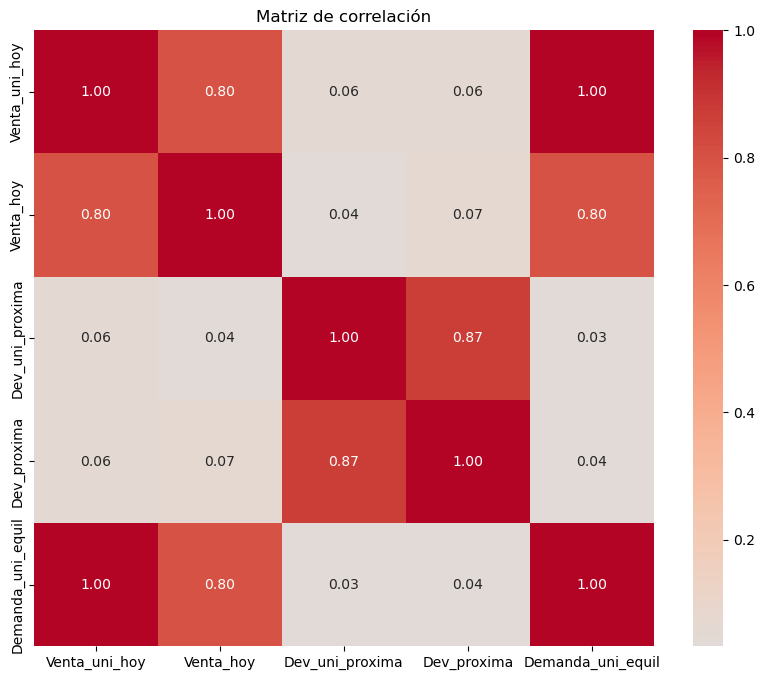

In [37]:
plt.figure(figsize=(10, 8))
sns.heatmap(final_df[varNumericas].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.show()
#Grafica de dataset de muestra 

## Histogramas y boxplots: completo vs. muestra

La primera celda usa el dataset completo y tarda unos 15 minutos. La segunda usa la muestra y es mucho más rápida.

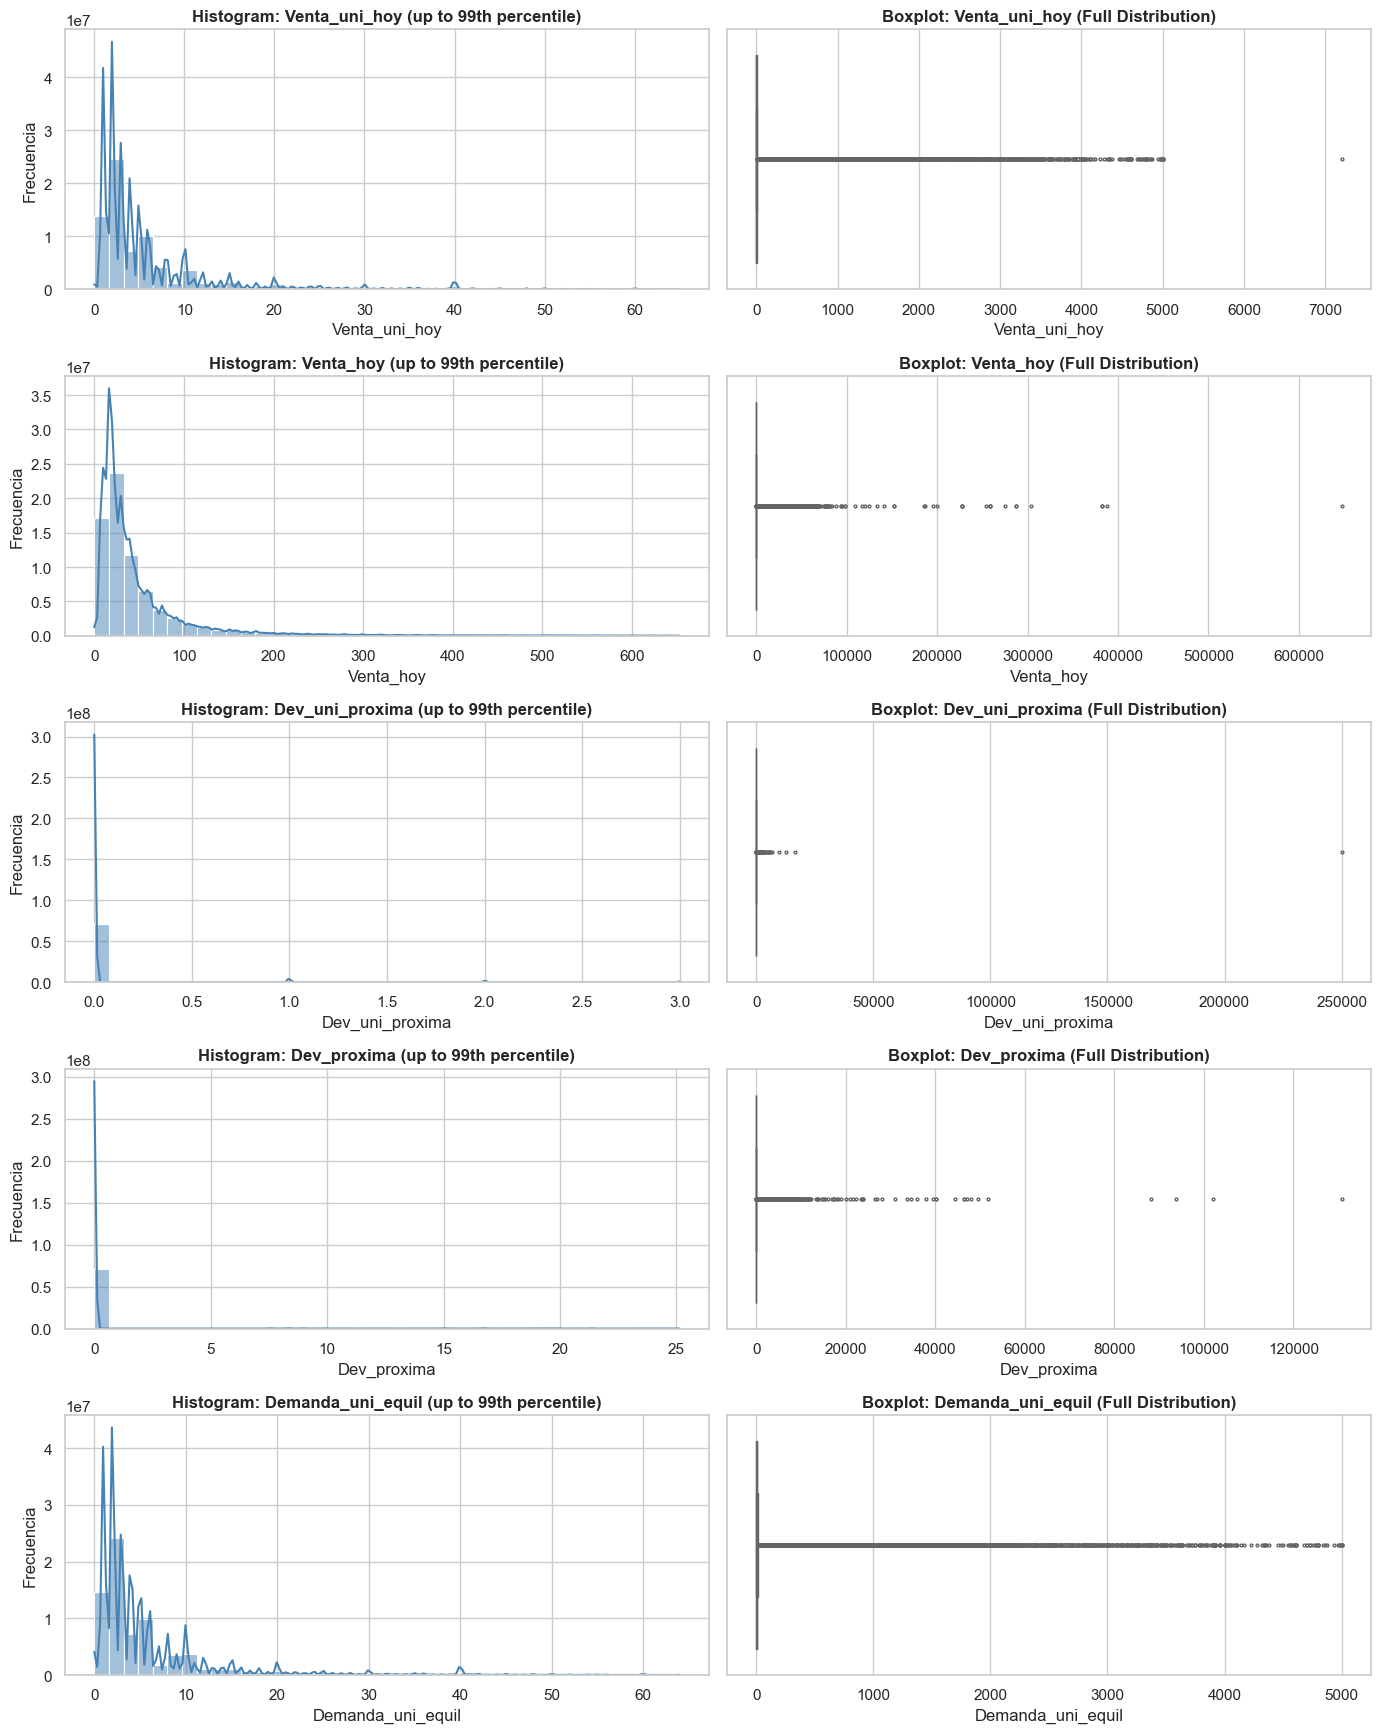

In [153]:

# Select the continuous numerical columns
numerical_cols = [
    'Venta_uni_hoy', 
    'Venta_hoy', 
    'Dev_uni_proxima', 
    'Dev_proxima', 
    'Demanda_uni_equil'
]

# Set theme style
sns.set_theme(style="whitegrid", palette="muted")

fig, axes = plt.subplots(len(numerical_cols), 2, figsize=(14, 3.5 * len(numerical_cols)))

for idx, col in enumerate(numerical_cols):
    # Clip at 99th percentile for visualization so extreme outliers don't crush the histogram
    p99 = df[col].quantile(0.99)
    subset = df[df[col] <= p99][col]
    
    # Left column: Histogram + KDE
    sns.histplot(subset, bins=40, kde=True, ax=axes[idx, 0], color='steelblue')
    axes[idx, 0].set_title(f'Histogram: {col} (up to 99th percentile)', fontweight='bold')
    axes[idx, 0].set_xlabel(col)
    axes[idx, 0].set_ylabel('Frecuencia')
    
    # Right column: Boxplot
    sns.boxplot(x=df[col], ax=axes[idx, 1], color='coral', fliersize=2)
    axes[idx, 1].set_title(f'Boxplot: {col} (Full Distribution)', fontweight='bold')
    axes[idx, 1].set_xlabel(col)

plt.tight_layout()
plt.show()

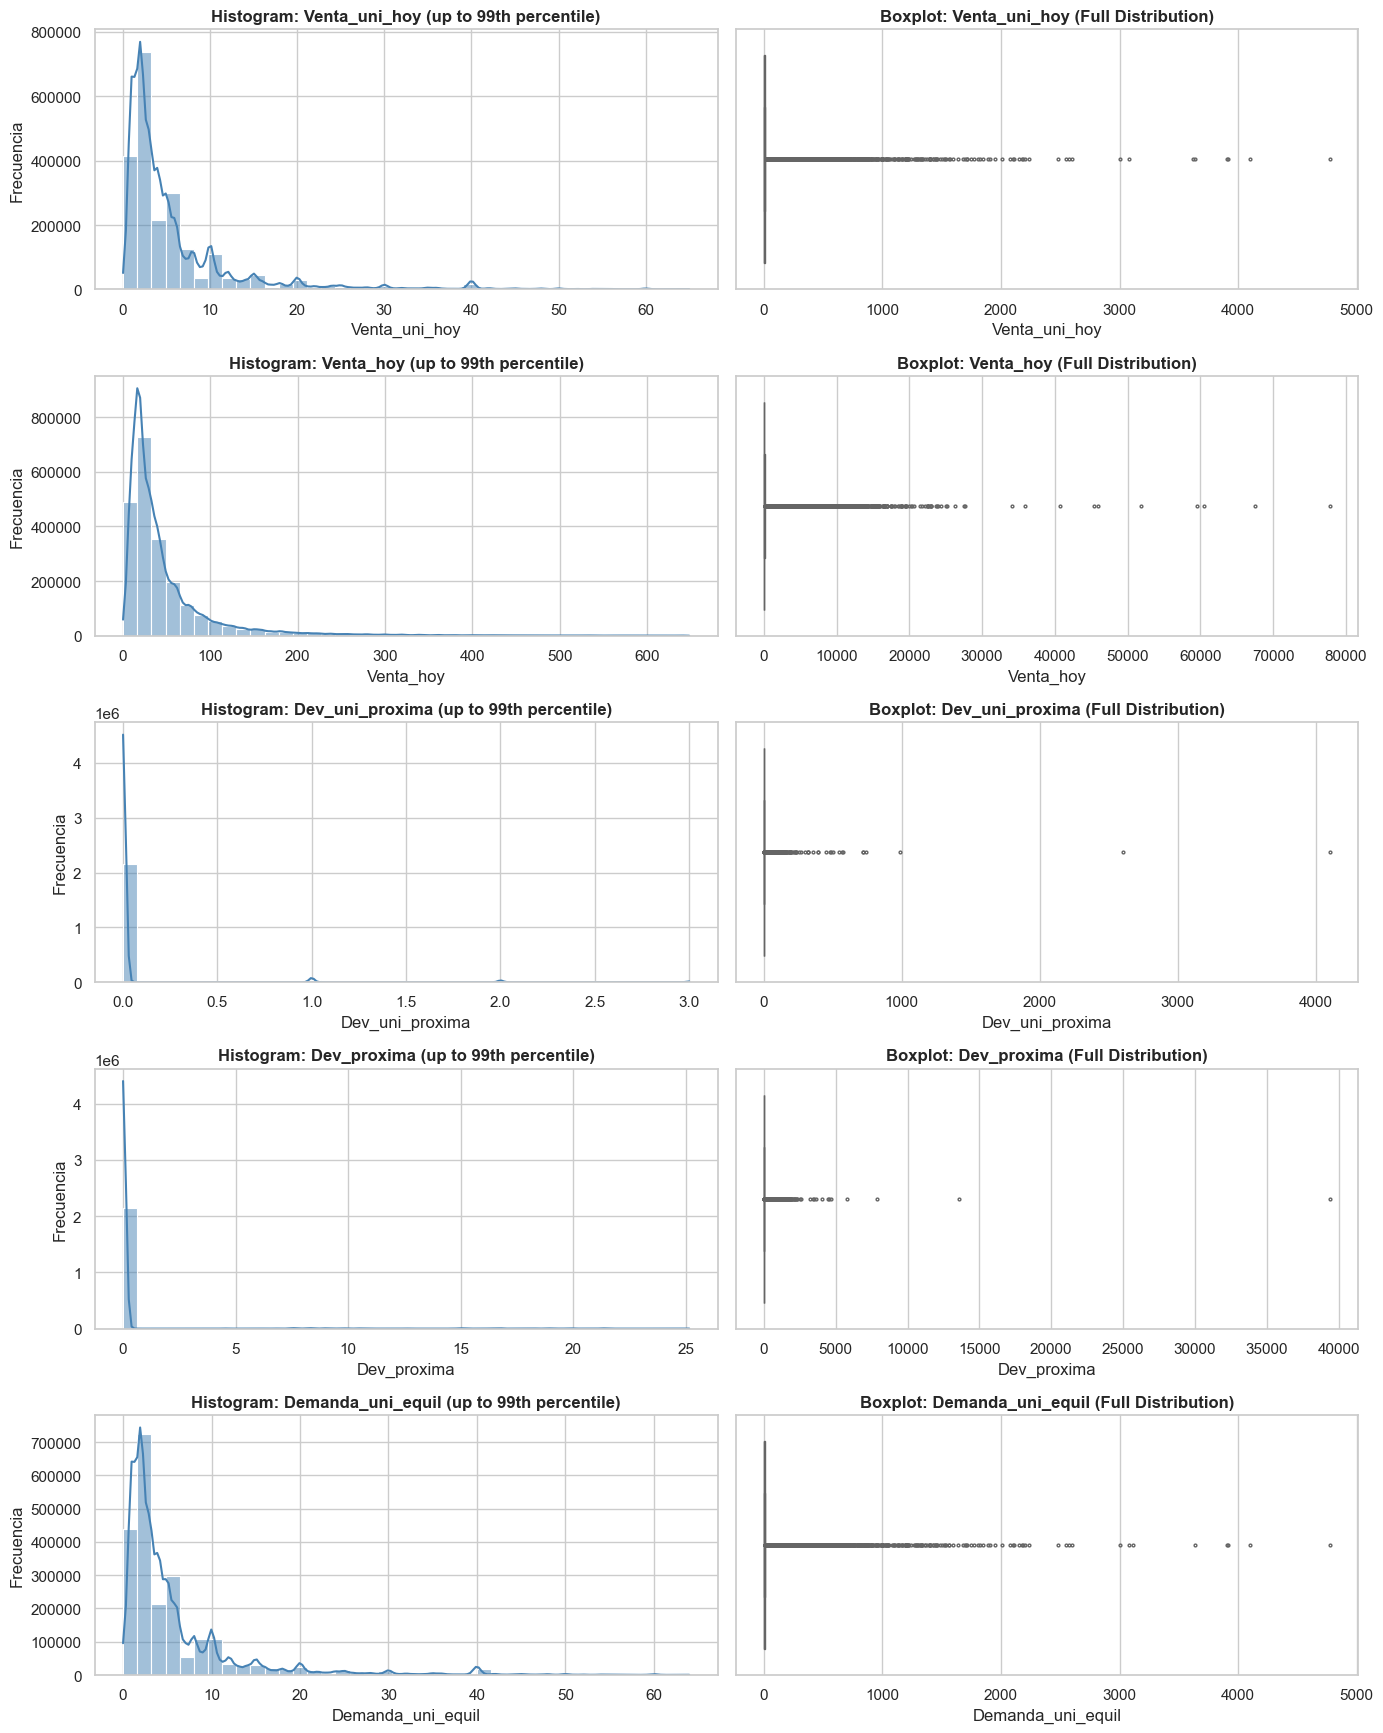

In [154]:
numerical_cols = [
    'Venta_uni_hoy', 
    'Venta_hoy', 
    'Dev_uni_proxima', 
    'Dev_proxima', 
    'Demanda_uni_equil'
]


sns.set_theme(style="whitegrid", palette="muted")

fig, axes = plt.subplots(len(numerical_cols), 2, figsize=(14, 3.5 * len(numerical_cols)))

for idx, col in enumerate(numerical_cols):
    
    p99 = final_df[col].quantile(0.99)
    subset = final_df[final_df[col] <= p99][col]
    
    # Histogram + KDE
    sns.histplot(subset, bins=40, kde=True, ax=axes[idx, 0], color='steelblue')
    axes[idx, 0].set_title(f'Histogram: {col} (up to 99th percentile)', fontweight='bold')
    axes[idx, 0].set_xlabel(col)
    axes[idx, 0].set_ylabel('Frecuencia')
    
    # Boxplot
    sns.boxplot(x=final_df[col], ax=axes[idx, 1], color='coral', fliersize=2)
    axes[idx, 1].set_title(f'Boxplot: {col} (Full Distribution)', fontweight='bold')
    axes[idx, 1].set_xlabel(col)

plt.tight_layout()
plt.show()

## Concentración de la demanda por producto

**Dataset usado: completo.** Aquí se necesitan los totales exactos de unidades, así que se calcula con los 74M de filas.

In [70]:
# Demanda total (unidades) por producto y semana, con los 74M de registros
demanda_semana = df.groupby(['Producto_ID', 'Semana'])['Demanda_uni_equil'].sum().unstack()

# Top 10 por unidades de demanda (no por numero de filas)
demanda_total = demanda_semana.sum(axis=1).sort_values(ascending=False)
top10 = demanda_total.head(10).index.tolist()

# Que porcentaje de las unidades cubren los top 10 y como se llaman
print(f"Top 10 cubre el {round(demanda_total.head(10).sum() / demanda_total.sum() * 100, 1)}% de las unidades")
print(productos.drop_duplicates('Producto_ID').set_index('Producto_ID')['NombreProducto'].reindex(top10))
demanda_semana.loc[top10]

Top 10 cubre el 27.3% de las unidades
Producto_ID
2425                 Nito 1p 62g Central BIM 2425
1284                     Rebanada 2p 55g BIM 1284
1278                         Nito 1p 62g BIM 1278
43285                Gansito 1p 50g MTB MLA 43285
36610       Bolsa Mini Rocko 40p 13g CU MLA 36610
1240         Mantecadas Vainilla 4p 125g BIM 1240
1250                Donas Azucar 4p 105g BIM 1250
2233                     Pan Blanco 640g BIM 2233
1242       Donitas Espolvoreadas 6p 105g BIM 1242
45143    Polvoroncitos Panera 40p 16 25g TR 45143
Name: NombreProducto, dtype: object


Semana,3,4,5,6,7,8,9
Producto_ID,,,,,,,
2425,2864024.0,3414616.0,3877425.0,3721666.0,3769585.0,3283817.0,2797541.0
1284,2245586.0,2643231.0,3057615.0,3206937.0,3277812.0,2766746.0,2341652.0
1278,2391500.0,2576050.0,2817563.0,3006123.0,3107164.0,2981463.0,2656733.0
43285,2357631.0,2184835.0,2103623.0,2071511.0,2152862.0,2135026.0,2152463.0
36610,1646979.0,1774988.0,1778944.0,1791560.0,1860439.0,1881953.0,1945380.0
1240,1899139.0,1838156.0,1776614.0,1714658.0,1707374.0,1626317.0,1604987.0
1250,1788198.0,1785487.0,1758698.0,1695077.0,1732525.0,1682751.0,1574328.0
2233,1704762.0,1603163.0,1528968.0,1447968.0,1569636.0,1605475.0,1641789.0
1242,1566166.0,1563903.0,1547549.0,1497551.0,1505179.0,1397902.0,1311004.0


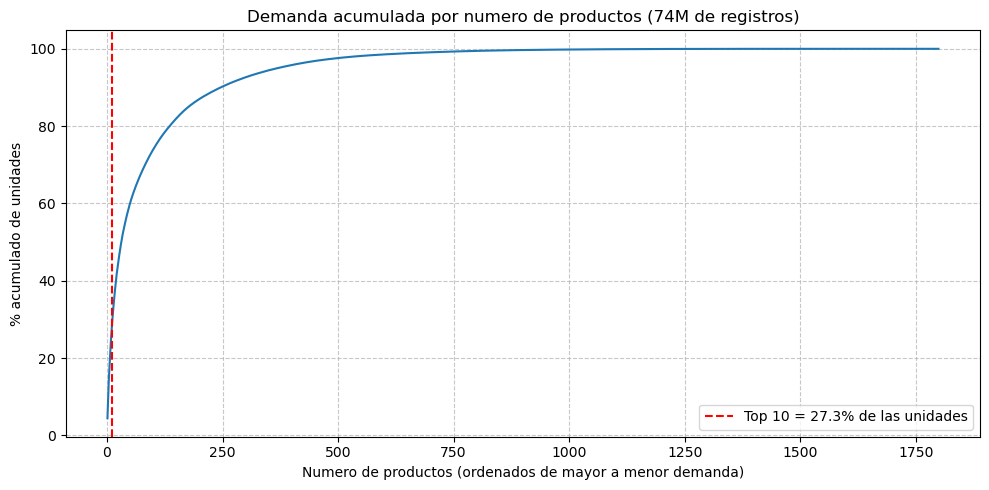

Producto_ID
45143    27.3
35309    60.1
33794    74.0
dtype: float64


In [72]:
acumulado = demanda_total.cumsum() / demanda_total.sum() * 100

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(acumulado) + 1), acumulado.values)
plt.axvline(10, color='red', linestyle='--', label=f'Top 10 = {acumulado.iloc[9]:.1f}% de las unidades')
plt.title('Demanda acumulada por numero de productos (74M de registros)')
plt.xlabel('Numero de productos (ordenados de mayor a menor demanda)')
plt.ylabel('% acumulado de unidades')
plt.legend()
plt.grid(linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print(acumulado.iloc[[9, 49, 99]].round(1))  # top 10, 50 y 100

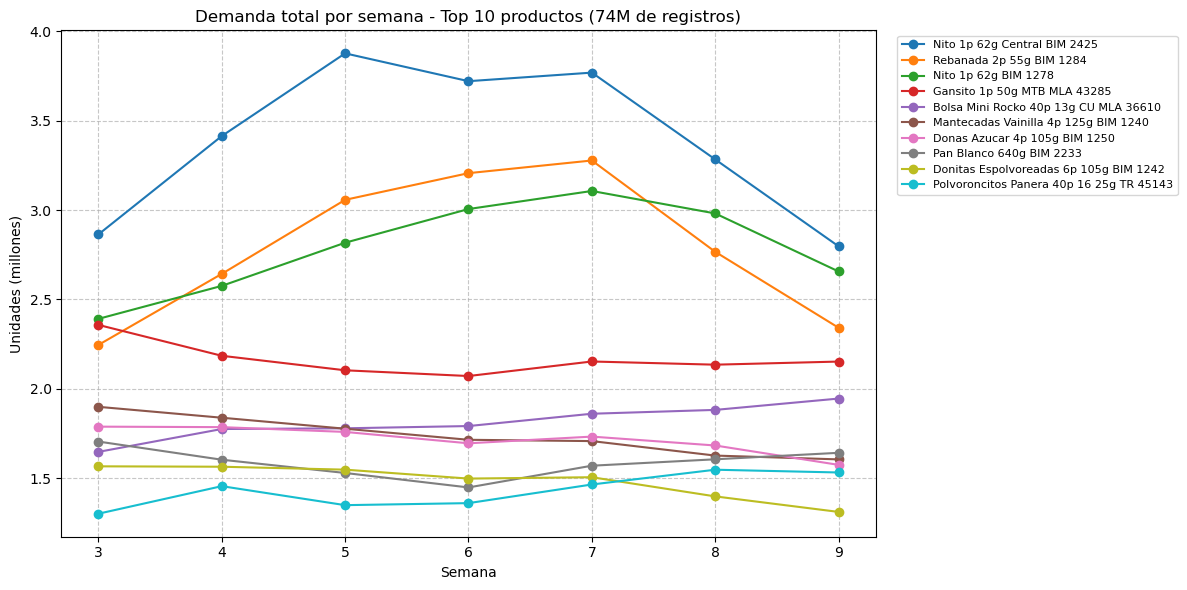

In [73]:
nombres = productos.drop_duplicates('Producto_ID').set_index('Producto_ID')['NombreProducto']
tabla = demanda_semana.loc[top10] / 1_000_000

plt.figure(figsize=(12, 6))
for pid in top10:
    plt.plot(tabla.columns, tabla.loc[pid], marker='o', label=nombres[pid])
plt.title('Demanda total por semana - Top 10 productos (74M de registros)')
plt.xlabel('Semana')
plt.ylabel('Unidades (millones)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.grid(linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Parte 4. Feature Engineering descriptivo (variables nuevas)

**Dataset usado: muestra.** A partir de aqui se agregan columnas nuevas a `final_df` (la muestra de 2.2M registros).

Estas variables describen **qué es** cada producto y **qué tipo** de tienda es cada cliente. Sirven para entender el negocio (gráficas de esta parte), pero **no entran al modelo**: no cambian de una semana a otra, y el modelo trabaja con el comportamiento en el tiempo. Las variables temporales del modelo se crean en la Parte 5.

## 1. Precio unitario

`Precio_unit = Venta_hoy / Venta_uni_hoy`. Es un cociente, asi que no contiene la cantidad vendida (no hay fuga de informacion).

In [65]:
# Si Venta_uni_hoy es 0 no se puede dividir: esos casos quedan como NaN
final_df['Precio_unit'] = (final_df['Venta_hoy'] / final_df['Venta_uni_hoy'].replace(0, np.nan)).astype('float32')

print(f"Filas sin precio (Venta_uni_hoy = 0): {final_df['Precio_unit'].isna().sum()}")
final_df['Precio_unit'].describe()

Filas sin precio (Venta_uni_hoy = 0): 9000


count    2.216414e+06
mean     1.009023e+01
std      6.018019e+00
min      2.600000e-01
25%      6.760000e+00
50%      8.380000e+00
75%      1.259000e+01
max      6.473600e+02
Name: Precio_unit, dtype: float64

## 2. Variables del producto (desde producto_tabla)

El nombre del producto trae informacion util, por ejemplo `Bimbollos Ext sAjonjoli 6p 480g BIM 41`:
* `piezas`: 6 (el numero antes de la `p`)
* `gramos`: 480 (si viene en Kg se pasa a gramos)
* `marca`: BIM (la palabra antes del ID final)
* `familia`: Bimbollos (la primera palabra)

In [66]:
import re

# Trabajamos con una tabla chica de productos (1.8k filas) y luego se une a final_df
productos_info = productos[['Producto_ID', 'NombreProducto']].drop_duplicates('Producto_ID').copy()
nombre = productos_info['NombreProducto']

# piezas: numero seguido de 'p' (ej. 6p). Si no aparece queda NaN
productos_info['piezas'] = nombre.str.extract(r'\b(\d+)p\b', flags=re.IGNORECASE)[0].astype('float32')

# gramaje: numero seguido de g, kg o ml. Si esta en kg se multiplica por 1000
medida = nombre.str.extract(r'(\d+(?:\.\d+)?)\s*(kg|g|ml)\b', flags=re.IGNORECASE)
cantidad = medida[0].astype('float32')
productos_info['gramos'] = cantidad.where(medida[1].str.lower() != 'kg', cantidad * 1000)

# marca: penultima palabra (la ultima es el ID). familia: primera palabra
productos_info['marca'] = nombre.str.split().str[-2].astype('category')
productos_info['familia'] = nombre.str.split().str[0].astype('category')

# Revisar que la extraccion tenga sentido antes de unir
print(productos_info.isna().sum())
productos_info.sample(10, random_state=42)

Producto_ID          0
NombreProducto       0
piezas            1468
gramos              57
marca                0
familia              0
dtype: int64


,Producto_ID,NombreProducto,piezas,gramos,marca,familia
2313,46111,Medias Noches 8p 340g TAB BIM 46111,8.0,340.0,BIM,Medias
2089,43131,Wonder 100pct mediano 475g MTA WON 43131,NaN,475.0,WON,Wonder
761,32220,Sandwich Blanco Jamon 90g Prom LON 32220,NaN,90.0,LON,Sandwich
829,32441,Tripack Tostada Clasica 720g CUB SAN 32441,NaN,720.0,SAN,Tripack
1961,40803,Nano Milk Lechero Besos Nuez 100g CU GBI 40803,NaN,100.0,GBI,Nano
194,3526,Canapinas 95g SP LAR 3526,NaN,95.0,LAR,Canapinas
1084,34187,Salma Dispenser 43p 516g CJM SAN 34187,43.0,516.0,SAN,Salma
1071,34078,Barritas Fresa Escolar 26 5g MTA MLA 34078,NaN,5.0,MLA,Barritas
1684,36691,Barritas Fresa Salvado MG 67g CR2 MLA 36691,NaN,67.0,MLA,Barritas
173,3030,Tostado Blanco 180g WON 3030,NaN,180.0,WON,Tostado


In [67]:
# Unimos a la muestra. 'left' para no perder filas de final_df
##CORRER UNA SOLA VEEEEEEEEEEEEEEZ
filas_antes = final_df.shape[0]
final_df = final_df.merge(productos_info.drop(columns='NombreProducto'), on='Producto_ID', how='left')

print(f"Filas antes: {filas_antes} | despues: {final_df.shape[0]} ")
final_df.head()

Filas antes: 2225414 | despues: 2225414 


,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil,Precio_unit,piezas,gramos,marca,familia
0,3,1130,1,1009,1046574,1146,1,21.389999,0,0.0,1,21.389999,NaN,675.0,BIM,Pan
1,3,1112,1,1010,327766,2233,5,99.699997,0,0.0,5,19.939999,NaN,640.0,BIM,Pan
2,3,1121,1,1624,197555,31298,3,26.670000,0,0.0,3,8.890000,NaN,210.0,TR,Duo
3,3,1120,1,2118,386617,36748,13,149.889999,0,0.0,13,11.530000,NaN,287.0,MLA,Polvorones
4,3,1111,1,1633,67057,303,6,27.240000,0,0.0,6,4.540000,1.0,55.0,MLA,Dalmata


## 3. Tipo de tienda (desde cliente_tabla)

`cliente_tabla` solo tiene el nombre de cada cliente. Buscamos palabras clave en el nombre (OXXO, ABARROTES, SUPER, ...) para clasificar cada tienda. El orden de las condiciones importa: gana la primera que coincida.

In [68]:
# Nombre de cada cliente de la muestra (map evita duplicar filas)
nombre_cliente = final_df['Cliente_ID'].map(clientes.drop_duplicates('Cliente_ID').set_index('Cliente_ID')['NombreCliente'])

# Los 30 nombres mas frecuentes y las 30 primeras palabras mas comunes
print(nombre_cliente.value_counts().head(30))
print(nombre_cliente.str.split().str[0].value_counts().head(30))

Cliente_ID
NO IDENTIFICADO    397717
LUPITA              13894
MARY                 8367
LA PASADITA          6208
LA VENTANITA         5129
LA GUADALUPANA       4200
ALEX                 3900
LA ESPERANZA         3750
PATY                 3732
PUEBLA REMISION      3707
GABY                 3519
LA CHIQUITA          3496
ROSY                 3427
DANY                 3393
LA PROVIDENCIA       3120
HERNANDEZ            3049
LA ESCONDIDA         3047
GARCIA               2921
LA ESQUINA           2825
SAN JOSE             2771
MARTINEZ             2702
DIANA                2691
LA ESTRELLA          2631
LA TIENDITA          2512
3 HERMANOS           2452
LUCY                 2441
MI TIENDITA          2419
GONZALEZ             2410
LETY                 2273
DICONSA              2216
Name: count, dtype: int64
Cliente_ID
NO            397820
LA            153379
ABARROTES      91437
EL             80209
OXXO           61080
SUPER          41387
MARIA          38152
MISCELANEA     32414
LOS 

In [88]:
# Tabla de clientes sin IDs repetidos; clasificamos por palabras clave en el nombre
clientes_tipo = clientes.drop_duplicates('Cliente_ID').copy()
nombre = clientes_tipo['NombreCliente'].fillna('NO IDENTIFICADO').str.upper()

# El orden importa: gana la primera condicion que coincida
condiciones = [
    nombre.str.contains('NO IDENTIFICADO|SIN NOMBRE'),
    nombre.str.contains('REMISION'),
    nombre.str.contains('DICONSA|LICONSA|ESCUELA|COLEGIO|HOSPITAL|UNIVERSIDAD'),
    nombre.str.contains('OXXO|ELEVEN'),
    nombre.str.contains('CREMERIA|FRUTERIA|FARMACIA|PANADERIA|CARNICERIA|TORTILLERIA|POLLERIA'),
    nombre.str.contains('ABARROTES|ABTS|MISCELANEA|TIENDA|TIENDITA'),
    nombre.str.contains(r'SUPER|\bMINI|WAL MART|WALMART|AURRERA|SORIANA|CHEDRAUI|COMERCIAL MEXICANA'),
]
tipos = ['No identificado', 'Remision', 'Institucional', 'Conveniencia (OXXO/7-Eleven)',
         'Comercio especializado', 'Abarrotes/Tienda de barrio', 'Supermercado/Minisuper']
clientes_tipo['tipo_tienda'] = np.select(condiciones, tipos, default='Otros (nombre propio)')

# Pasamos el tipo a la muestra (clientes que no estan en la tabla = No identificado)
final_df['tipo_tienda'] = (final_df['Cliente_ID']
    .map(clientes_tipo.set_index('Cliente_ID')['tipo_tienda'])
    .fillna('No identificado').astype('category'))

# Revision: cuantas filas cae en cada tipo y que quedo dentro de "Otros"
print((final_df['tipo_tienda'].value_counts(normalize=True) * 100).round(1))
otros = final_df['tipo_tienda'] == 'Otros (nombre propio)'


tipo_tienda
Otros (nombre propio)           65.5
No identificado                 17.9
Abarrotes/Tienda de barrio       6.7
Supermercado/Minisuper           3.9
Conveniencia (OXXO/7-Eleven)     3.2
Comercio especializado           1.9
Institucional                    0.7
Remision                         0.2
Name: proportion, dtype: float64


In [71]:
# Ajuste: reclasifica solo lo que quedo en "Otros" con dos palabras clave que faltaban
sin_tipo = clientes_tipo['tipo_tienda'] == 'Otros (nombre propio)'
clientes_tipo.loc[sin_tipo & nombre.str.contains('MISC'), 'tipo_tienda'] = 'Abarrotes/Tienda de barrio'
clientes_tipo.loc[sin_tipo & nombre.str.contains('PAPELERIA'), 'tipo_tienda'] = 'Comercio especializado'

final_df['tipo_tienda'] = (final_df['Cliente_ID']
    .map(clientes_tipo.set_index('Cliente_ID')['tipo_tienda'])
    .fillna('No identificado').astype('category'))

# Contraste: % de cada tipo de tienda en cada Canal_ID (cada fila suma 100)
print((pd.crosstab(final_df['tipo_tienda'], final_df['Canal_ID'], normalize='index') * 100).round(1))

Canal_ID                        1     2     4      5     6    7    8    9   \
tipo_tienda                                                                  
Abarrotes/Tienda de barrio    97.7   0.1   1.6    0.0   0.0  0.3  0.0  0.0   
Comercio especializado        88.2   0.0   9.2    0.0   0.1  1.0  0.0  0.0   
Conveniencia (OXXO/7-Eleven)   7.1   0.2  92.7    0.0   0.0  0.0  0.0  0.0   
Institucional                 65.6   1.3   4.9    0.0  11.7  4.5  0.4  0.0   
No identificado               89.8   0.6   5.1    0.0   0.4  1.4  0.2  0.0   
Otros (nombre propio)         96.0   0.5   1.0    0.0   0.3  0.9  0.1  0.0   
Remision                       0.0   0.0   0.0  100.0   0.0  0.0  0.0  0.0   
Supermercado/Minisuper        78.2  17.0   4.4    0.0   0.1  0.2  0.0  0.0   

Canal_ID                        11  
tipo_tienda                         
Abarrotes/Tienda de barrio     0.2  
Comercio especializado         1.5  
Conveniencia (OXXO/7-Eleven)   0.0  
Institucional                 11.6

In [87]:
final_df[(final_df['tipo_tienda'] != 'Otros (nombre propio)') & (final_df['tipo_tienda'] != 'No identificado')].head()

,Semana,Agencia_ID,Canal_ID,Ruta_SAK,Cliente_ID,Producto_ID,Venta_uni_hoy,Venta_hoy,Dev_uni_proxima,Dev_proxima,Demanda_uni_equil,Precio_unit,piezas,gramos,marca,familia,tipo_tienda
9,3,1123,1,1601,409737,9217,3,27.000000,0,0.0,3,9.000000,3.0,150.0,TR,Cuernitos,Institucional
23,3,1129,2,82,22702,43227,54,1090.800049,0,0.0,54,20.200001,NaN,500.0,BIM,Pan,Supermercado/Minisuper
27,3,1129,2,90,22699,31520,20,568.400024,0,0.0,20,28.420002,NaN,719.0,MLA,Principe,Supermercado/Minisuper
41,3,1111,1,1415,65514,48417,3,13.740000,0,0.0,3,4.580000,NaN,48.0,BIM,Bran,Abarrotes/Tienda de barrio
64,3,1124,1,1083,1653055,1160,1,18.860001,0,0.0,1,18.860001,8.0,450.0,BIM,Bimbollos,Abarrotes/Tienda de barrio


## 4. Gráficas con las variables nuevas

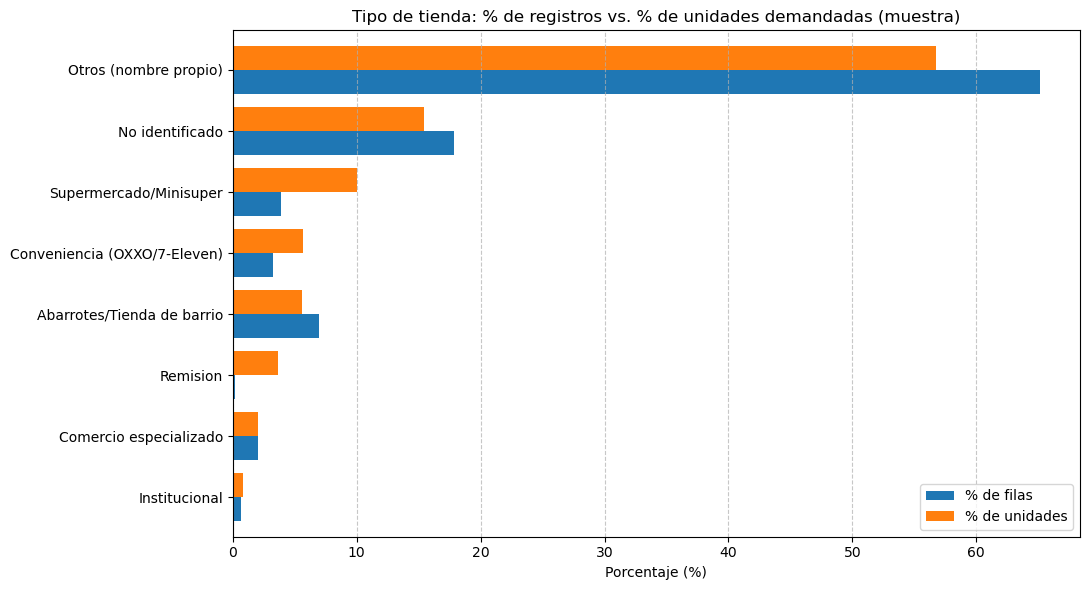

In [74]:
pct_filas = final_df['tipo_tienda'].value_counts(normalize=True) * 100
unidades = final_df.groupby('tipo_tienda', observed=True)['Demanda_uni_equil'].sum()
pct_unidades = unidades / unidades.sum() * 100

comparacion_tipo = pd.DataFrame({'% de filas': pct_filas, '% de unidades': pct_unidades}).sort_values('% de unidades')
comparacion_tipo.plot(kind='barh', figsize=(11, 6), width=0.8)
plt.title('Tipo de tienda: % de registros vs. % de unidades demandadas (muestra)')
plt.xlabel('Porcentaje (%)')
plt.ylabel('')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

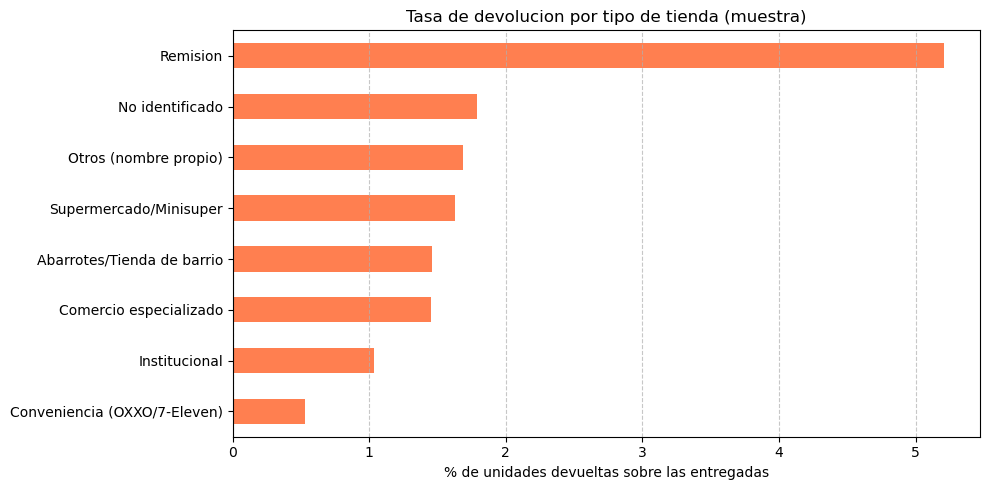

In [75]:
# Solo descriptiva: devoluciones / unidades entregadas. NO se usa como variable del modelo
merma = final_df.groupby('tipo_tienda', observed=True)[['Dev_uni_proxima', 'Venta_uni_hoy']].sum()
tasa_dev = (merma['Dev_uni_proxima'] / merma['Venta_uni_hoy'] * 100).sort_values()

plt.figure(figsize=(10, 5))
tasa_dev.plot(kind='barh', color='coral')
plt.title('Tasa de devolucion por tipo de tienda (muestra)')
plt.xlabel('% de unidades devueltas sobre las entregadas')
plt.ylabel('')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

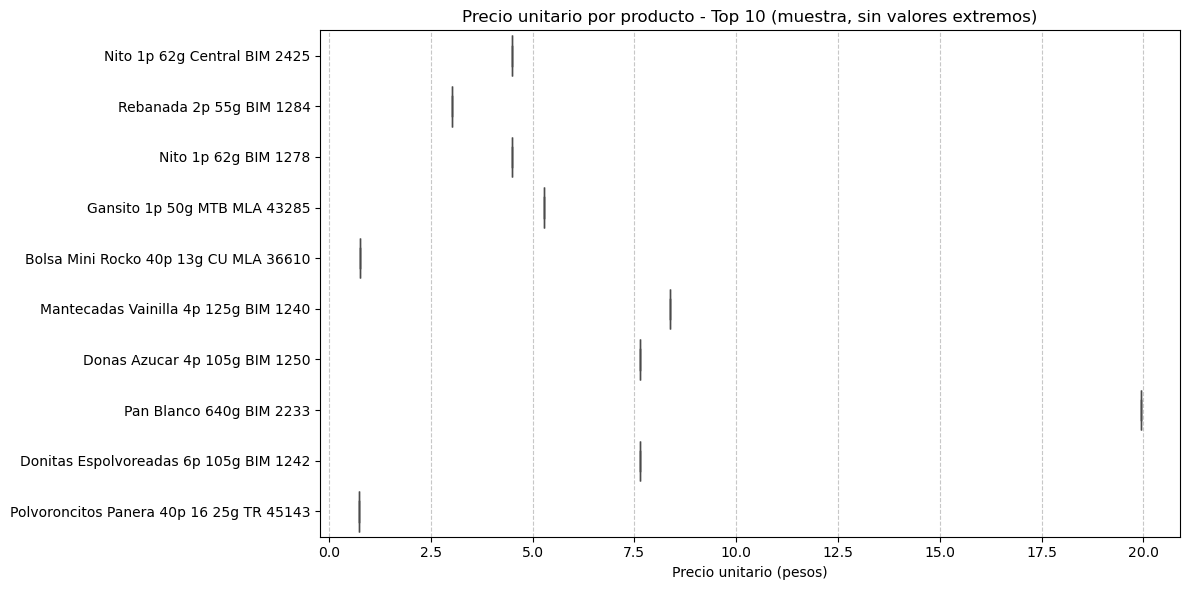

In [76]:
nombres = productos.drop_duplicates('Producto_ID').set_index('Producto_ID')['NombreProducto']

sub = final_df[final_df['Producto_ID'].isin(top10) & final_df['Precio_unit'].notna()].copy()
sub['Producto'] = sub['Producto_ID'].map(nombres)

plt.figure(figsize=(12, 6))
sns.boxplot(data=sub, y='Producto', x='Precio_unit', order=[nombres[p] for p in top10],
            showfliers=False, color='steelblue')
plt.title('Precio unitario por producto - Top 10 (muestra, sin valores extremos)')
plt.xlabel('Precio unitario (pesos)')
plt.ylabel('')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [77]:
print((final_df['Canal_ID'].value_counts(normalize=True) * 100).round(1))

Canal_ID
1     90.9
4      5.1
11     1.3
2      1.1
7      0.9
6      0.4
5      0.2
8      0.1
9      0.0
Name: proportion, dtype: float64


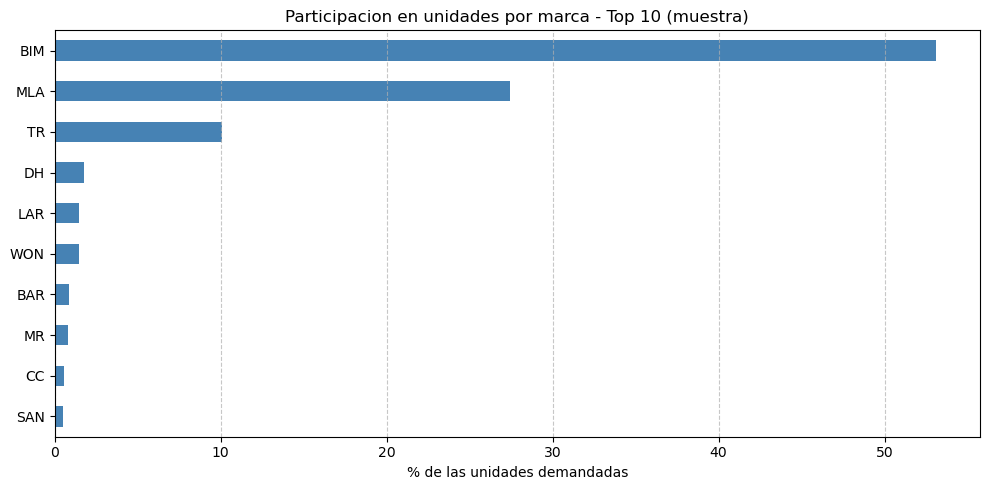

In [78]:
# % de las unidades demandadas que aporta cada marca (top 10 marcas, muestra)
unidades_marca = final_df.groupby('marca', observed=True)['Demanda_uni_equil'].sum()
pct_marca = (unidades_marca / unidades_marca.sum() * 100).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
pct_marca.sort_values().plot(kind='barh', color='steelblue')
plt.title('Participacion en unidades por marca - Top 10 (muestra)')
plt.xlabel('% de las unidades demandadas')
plt.ylabel('')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

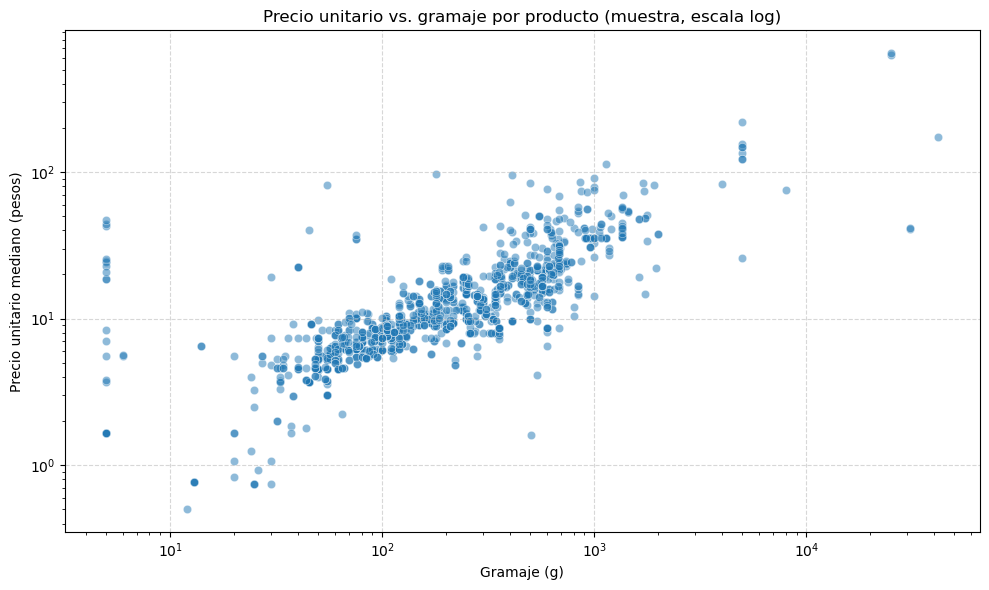

In [79]:
# Un punto por producto: precio mediano vs gramaje (escala log por la dispersion)
por_producto = final_df.groupby('Producto_ID').agg(
    precio=('Precio_unit', 'median'),
    gramaje=('gramos', 'first'),
    unidades=('Demanda_uni_equil', 'sum')
).dropna()
por_producto = por_producto[(por_producto['precio'] > 0) & (por_producto['gramaje'] > 0)]

plt.figure(figsize=(10, 6))
sns.scatterplot(data=por_producto, x='gramaje', y='precio', alpha=0.5)
plt.xscale('log')
plt.yscale('log')
plt.title('Precio unitario vs. gramaje por producto (muestra, escala log)')
plt.xlabel('Gramaje (g)')
plt.ylabel('Precio unitario mediano (pesos)')
plt.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Parte 5. Secuencias de tiempo

**Dataset usado: completo, agregado por Agencia × Producto × Semana.**

**¿Por qué no usamos la muestra para el modelo?** La muestra se hizo eligiendo filas al azar. Una tienda con un producto tiene 7 filas (una por semana), y la probabilidad de conservar las 7 en una muestra del 3% es 0.03⁷ ≈ 0.00000000002. Es decir, las series quedan rotas.

**¿Qué es una serie?** Sumamos la demanda de todos los clientes de una agencia para cada producto y semana. Una serie es, por ejemplo, *"el Pan Blanco de la agencia 1110 de la semana 3 a la 9"*. La agencia es el centro de distribución donde se cargan los camiones, así que la pregunta del modelo es: **¿cuántas unidades de cada producto se van a demandar en cada agencia la próxima semana?**

Al agregar, los 74M de filas se convierten en unas 54 mil series. Nos quedamos solo con las que tienen las 7 semanas completas.

In [ ]:
# Variables que sumamos por semana (una fila por Agencia x Producto x Semana)
cols = ['Venta_uni_hoy', 'Venta_hoy', 'Dev_uni_proxima', 'Dev_proxima', 'Demanda_uni_equil']
semanas = list(range(3, 10))

agg = df.groupby(['Agencia_ID', 'Producto_ID', 'Semana'])[cols].sum().astype('float64')

# Una fila por serie (Agencia, Producto) y una columna por (variable, semana)
wide = agg.unstack('Semana')
wide = wide.dropna()  # nos quedamos con las series que tienen las 7 semanas
wide = wide.reindex(columns=pd.MultiIndex.from_product([cols, semanas]))
print(f"Series con las 7 semanas: {wide.shape[0]}")

# Demo rapida: usamos una parte de las series
# Ya no hace falta: con ~54 mil series usamos todas
# wide = wide.sample(n=min(50_000, len(wide)), random_state=42)

In [ ]:
# Asi se ve la demanda de algunas series: una fila por (Agencia, Producto) y una columna por semana
wide['Demanda_uni_equil'].head()

## 5.1 Variables temporales (Feature Engineering para el modelo)

El dataset no tiene fechas, solo el número de semana. Por eso **no se pueden crear** variables como día de la semana, mes, fin de semana o feriado. Las variables temporales que sí se pueden crear salen del historial de cada serie:

| Variable | Qué mide | Ejemplo (demanda 100, 120, 90) |
|---|---|---|
| Semana anterior | La demanda de la última semana | 90 |
| Media móvil (3 semanas) | El promedio de las últimas 3 semanas | (100+120+90)/3 = 103.3 |
| Cambio % | Cuánto subió o bajó respecto a la semana anterior | (90−120)/120 = −25% |

La *semana anterior* ya la recibe el LSTM, porque le damos las semanas previas como secuencia. La **media móvil** y el **cambio %** se agregan como 2 columnas nuevas en cada semana.

In [ ]:
# Demanda en unidades: matriz de (series, 7 semanas)
demanda = wide['Demanda_uni_equil'].values

# Media movil: promedio de la semana actual y las 2 anteriores
# (en las primeras semanas se promedia lo que haya: la semana 3 sola, luego 3 y 4, ...)
media_movil = np.zeros_like(demanda)
for t in range(demanda.shape[1]):
    inicio = max(0, t - 2)
    media_movil[:, t] = demanda[:, inicio:t + 1].mean(axis=1)

# Cambio %: (semana actual - semana anterior) / semana anterior
# La semana 3 no tiene semana anterior, asi que su cambio queda en 0
cambio_pct = np.zeros_like(demanda)
for t in range(1, demanda.shape[1]):
    anterior = demanda[:, t - 1]
    actual = demanda[:, t]
    # Si la semana anterior fue 0 no se puede dividir: dejamos el cambio en 0
    cambio_pct[:, t] = np.where(anterior > 0, (actual - anterior) / np.maximum(anterior, 1), 0)

# Recortamos los valores extremos (ej. pasar de 1 a 500 unidades = +49,900%)
# para que no dominen la normalizacion: el cambio queda entre -100% y +300%
cambio_pct = np.clip(cambio_pct, -1, 3)

print(f"Media movil: {media_movil.shape} | Cambio %: {cambio_pct.shape}")

In [ ]:
# Ejemplo con una serie: como quedan las variables temporales semana a semana
ejemplo = pd.DataFrame({
    'Demanda': demanda[0],
    'Media movil (3 sem)': media_movil[0].round(1),
    'Cambio %': (cambio_pct[0] * 100).round(1)
}, index=[f'Semana {s}' for s in semanas])

print(f"Serie: Agencia {wide.index[0][0]}, Producto {wide.index[0][1]}")
ejemplo

## 5.2 Normalización

Juntamos las 5 columnas originales con las 2 variables temporales y normalizamos todo entre 0 y 1. El *scaler* se ajusta solo con las semanas 3 a 8: la semana 9 es la prueba final y el modelo no debe conocerla de antemano.

Las ventas y devoluciones sí entran, pero **solo de semanas anteriores**. Saber cuánto se entregó y cuánto volvió la semana pasada es información que se conoce antes de predecir, así que no hay fuga.

In [ ]:
from sklearn.preprocessing import MinMaxScaler

DEM = 4    # posicion de Demanda_uni_equil dentro de cols
N_SEM = 3  # semanas que mira la red (como las "3 horas" de la guia)

# Forma: (series, 7 semanas, 5 variables)
datos = wide.values.reshape(len(wide), len(cols), len(semanas)).transpose(0, 2, 1)

# log1p: la demanda tiene cola muy larga; asi la normalizacion no se aplasta
datos = np.log1p(datos)

# NUEVO: agregamos las 2 variables temporales -> forma (series, 7 semanas, 7 variables)
# La media movil esta en unidades, asi que tambien lleva log1p. El cambio % ya es un numero pequeno
datos = np.concatenate([datos,
                        np.log1p(media_movil)[:, :, np.newaxis],
                        cambio_pct[:, :, np.newaxis]], axis=2)
nombres_variables = cols + ['Media_movil', 'Cambio_pct']
print(f"Forma de los datos: {datos.shape}  ->  variables: {nombres_variables}")

# Normalizamos (0-1) ajustando solo con las semanas de entrenamiento (3 a 8)
# (ahora son 7 variables, por eso se usa datos.shape[2])
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(datos[:, :6, :].reshape(-1, datos.shape[2]))
datos_esc = scaler.transform(datos.reshape(-1, datos.shape[2])).reshape(datos.shape)

## 5.3 Ventanas de tiempo y división en entrenamiento, validación y prueba

Cada ejemplo del modelo es: **entrada = las N semanas anteriores**, **salida = la demanda de la semana siguiente**. Probamos dos tamaños de ventana, igual que la guía del profesor probó 1 hora y 3 horas:

| Ventana | Entrenamiento (semanas objetivo) | Validación | Prueba |
|---|---|---|---|
| 1 semana | 4, 5, 6, 7 | 8 | 9 |
| 3 semanas | 6, 7 | 8 | 9 |

Con ventana de 3, las semanas 4 y 5 no pueden ser objetivo porque no tienen 3 semanas antes. Con ventana de 1 hay más ejemplos, pero cada uno ve menos historia.

* **Validación (semana 8):** para comparar modelos y elegir hiperparámetros.
* **Prueba (semana 9):** se usa **una sola vez**, al final, con el modelo elegido.
* El `test.csv` de Kaggle **no se usa**: no tiene `Demanda_uni_equil`, así que no hay contra qué calcular el RMSE.

In [ ]:
# Entrada = N semanas anteriores, salida = demanda de la semana siguiente
# NUEVO: n_sem y variables son parametros, para poder probar ventana de 1 y de 3,
# y para probar el modelo con y sin las variables temporales
def ventanas(datos_esc, semanas_objetivo, n_sem=N_SEM, variables=None):
    if variables is None:
        variables = list(range(datos_esc.shape[2]))  # todas las variables
    X = np.concatenate([datos_esc[:, (s-3)-n_sem:(s-3), :][:, :, variables] for s in semanas_objetivo])
    y = np.concatenate([datos_esc[:, s-3, DEM] for s in semanas_objetivo])
    return X, y

# Semanas objetivo de entrenamiento segun el tamano de la ventana
# (la primera semana que se puede predecir es 3 + n_sem; la 8 queda para validacion)
def semanas_entrenamiento(n_sem):
    return list(range(3 + n_sem, 8))

SEMANA_VAL = 8
SEMANA_TEST = 9

VARS_ORIGINALES = [0, 1, 2, 3, 4]               # las 5 columnas de cols
VARS_CON_TEMPORALES = [0, 1, 2, 3, 4, 5, 6]     # + Media_movil y Cambio_pct

for n in [1, 3]:
    train_X, train_y = ventanas(datos_esc, semanas_entrenamiento(n), n)
    print(f"Ventana de {n}: entrena con semanas {semanas_entrenamiento(n)} -> X {train_X.shape}, "
          f"valida con [{SEMANA_VAL}], prueba con [{SEMANA_TEST}]")

# Parte 6. Modelos y finetuning

**Dataset usado: completo, agregado.**

**Métrica: RMSE** (raíz del error cuadrático medio), en unidades reales:

RMSE = √( promedio de (real − predicho)² )

Un RMSE de 500 significa que, en promedio, el modelo se equivoca en unas 500 unidades por serie. Penaliza más los errores grandes.

**Modelo de referencia (ingenuo):** predecir que la próxima semana se demanda lo mismo que la semana anterior. Si el LSTM no le gana a esto, no sirve.

In [ ]:
from math import sqrt
from sklearn.metrics import mean_squared_error

# Regresamos de la escala 0-1 a unidades reales
def a_unidades(y_esc):
    y_log = y_esc * (scaler.data_max_[DEM] - scaler.data_min_[DEM]) + scaler.data_min_[DEM]
    return np.maximum(np.expm1(y_log), 0)

# RMSE en unidades reales (no en la escala 0-1)
def rmse_unidades(y_esc_real, y_esc_pred):
    return sqrt(mean_squared_error(a_unidades(y_esc_real), a_unidades(y_esc_pred)))

# Modelo ingenuo en validacion: la demanda de la semana 8 = la de la semana 7
val_X, val_y = ventanas(datos_esc, [SEMANA_VAL], 1)
rmse_ingenuo_val = rmse_unidades(val_y, val_X[:, -1, DEM])
print(f"RMSE ingenuo en validacion (semana 8): {rmse_ingenuo_val:.2f}")

## 6.1 Diseño del modelo

Misma arquitectura que la guía: una capa **LSTM** y una capa **Dense(1)** que da la demanda. Agregamos dos cosas:
* **Dropout** (opcional): apaga neuronas al azar durante el entrenamiento para que el modelo no memorice.
* **EarlyStopping:** si el error de validación no mejora en 3 épocas seguidas, se detiene y se queda con la mejor época.

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

os.makedirs('figuras', exist_ok=True)  # aqui se guardan las graficas para las diapositivas

def crear_modelo(n_sem, n_variables, neuronas=50, dropout=0.0):
    model = Sequential()
    model.add(Input(shape=(n_sem, n_variables)))
    model.add(LSTM(neuronas))
    if dropout > 0:
        model.add(Dropout(dropout))
    model.add(Dense(1))
    model.compile(loss='mae', optimizer='adam')
    return model

def entrenar(n_sem, variables, neuronas=50, dropout=0.0, epochs=20):
    # Entrena con las semanas de entrenamiento y mide el RMSE en validacion (semana 8)
    tf.keras.utils.set_random_seed(42)  # misma semilla en todos -> resultados comparables

    train_X, train_y = ventanas(datos_esc, semanas_entrenamiento(n_sem), n_sem, variables)
    val_X, val_y = ventanas(datos_esc, [SEMANA_VAL], n_sem, variables)

    model = crear_modelo(n_sem, len(variables), neuronas, dropout)
    parada = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
    history = model.fit(train_X, train_y, epochs=epochs, batch_size=512,
                        validation_data=(val_X, val_y), callbacks=[parada], verbose=0)

    rmse_val = rmse_unidades(val_y, model.predict(val_X, verbose=0).ravel())
    mejor_epoca = int(np.argmin(history.history['val_loss'])) + 1
    return model, history, rmse_val, mejor_epoca

## 6.2 Experimento 1: ventana de 1 vs. 3 semanas, con y sin variables temporales

Entrenamos 4 modelos iguales (LSTM de 50 neuronas) cambiando solo dos cosas: cuántas semanas mira y si recibe las variables temporales. Se comparan con el RMSE de validación (semana 8).

In [ ]:
opciones_variables = [('Originales (5)', VARS_ORIGINALES),
                      ('Con temporales (7)', VARS_CON_TEMPORALES)]

resultados_exp1 = []
for n_sem in [1, 3]:
    for nombre_vars, variables in opciones_variables:
        model, history, rmse_val, mejor_epoca = entrenar(n_sem, variables)
        resultados_exp1.append({'Ventana': n_sem, 'Variables': nombre_vars,
                                'Mejor epoca': mejor_epoca, 'RMSE validacion': round(rmse_val, 2)})
        print(f"Ventana {n_sem} | {nombre_vars} | RMSE validacion: {rmse_val:.2f}")

tabla_exp1 = pd.DataFrame(resultados_exp1)
tabla_exp1

In [ ]:
# Grafica del experimento 1 (para las diapositivas)
etiquetas = [f"Ventana {r['Ventana']}\n{r['Variables']}" for _, r in tabla_exp1.iterrows()]

plt.figure(figsize=(9, 5))
plt.bar(etiquetas, tabla_exp1['RMSE validacion'], color='steelblue')
plt.axhline(rmse_ingenuo_val, color='red', linestyle='--', label=f'Ingenuo (semana anterior) = {rmse_ingenuo_val:.1f}')
for i, valor in enumerate(tabla_exp1['RMSE validacion']):
    plt.text(i, valor, f'{valor:.1f}', ha='center', va='bottom')
plt.title('Experimento 1: RMSE en validacion (semana 8)')
plt.ylabel('RMSE (unidades)')
plt.legend()
plt.tight_layout()
plt.savefig('figuras/exp1_ventana_variables.png', dpi=150)
plt.show()

# Nos quedamos con la combinacion de menor RMSE
mejor = tabla_exp1.loc[tabla_exp1['RMSE validacion'].idxmin()]
MEJOR_N_SEM = int(mejor['Ventana'])
MEJORES_VARS = VARS_ORIGINALES if mejor['Variables'] == 'Originales (5)' else VARS_CON_TEMPORALES
print(f"Mejor combinacion: ventana de {MEJOR_N_SEM} semana(s), variables {mejor['Variables']}")

## 6.3 Experimento 2: finetuning de hiperparámetros

Con la mejor ventana y el mejor grupo de variables, probamos 6 configuraciones: **neuronas** (25, 50, 100) × **dropout** (0 y 0.2). Se elige la de menor RMSE en validación.

In [ ]:
resultados_exp2 = []
for neuronas in [25, 50, 100]:
    for dropout in [0.0, 0.2]:
        model, history, rmse_val, mejor_epoca = entrenar(MEJOR_N_SEM, MEJORES_VARS, neuronas, dropout)
        resultados_exp2.append({'Neuronas': neuronas, 'Dropout': dropout,
                                'Mejor epoca': mejor_epoca, 'RMSE validacion': round(rmse_val, 2)})
        print(f"Neuronas {neuronas} | Dropout {dropout} | RMSE validacion: {rmse_val:.2f}")

tabla_exp2 = pd.DataFrame(resultados_exp2).sort_values('RMSE validacion').reset_index(drop=True)
tabla_exp2

In [ ]:
# Mejor configuracion del finetuning (primera fila, porque la tabla esta ordenada)
mejor_conf = tabla_exp2.iloc[0]
MEJORES_NEURONAS = int(mejor_conf['Neuronas'])
MEJOR_DROPOUT = float(mejor_conf['Dropout'])
MEJORES_EPOCAS = int(mejor_conf['Mejor epoca'])
print(f"Modelo elegido: ventana {MEJOR_N_SEM}, {len(MEJORES_VARS)} variables, "
      f"{MEJORES_NEURONAS} neuronas, dropout {MEJOR_DROPOUT}, {MEJORES_EPOCAS} epocas")

## 6.4 Modelo final y evaluación en la semana 9 (prueba)

Ahora que ya elegimos todo, entrenamos el modelo final **sumando la semana 8 al entrenamiento** (ya no hace falta validación) con el número de épocas que funcionó mejor. Después lo evaluamos **una sola vez** en la semana 9.

In [ ]:
tf.keras.utils.set_random_seed(42)

# Entrenamiento = semanas de entrenamiento + la semana 8
semanas_finales = semanas_entrenamiento(MEJOR_N_SEM) + [SEMANA_VAL]
train_X, train_y = ventanas(datos_esc, semanas_finales, MEJOR_N_SEM, MEJORES_VARS)
test_X, test_y = ventanas(datos_esc, [SEMANA_TEST], MEJOR_N_SEM, MEJORES_VARS)
print(f"Entrena con semanas {semanas_finales}: {train_X.shape} | Prueba con semana {SEMANA_TEST}: {test_X.shape}")

modelo_final = crear_modelo(MEJOR_N_SEM, len(MEJORES_VARS), MEJORES_NEURONAS, MEJOR_DROPOUT)
history = modelo_final.fit(train_X, train_y, epochs=MEJORES_EPOCAS, batch_size=512, verbose=2)

plt.plot(history.history['loss'], label='train')
plt.legend()
plt.show()

In [ ]:
y_real = a_unidades(test_y)
y_pred = a_unidades(modelo_final.predict(test_X).ravel())
y_base = a_unidades(test_X[:, -1, DEM])  # modelo ingenuo: repetir la semana anterior

rmse_lstm = sqrt(mean_squared_error(y_real, y_pred))
rmse_base = sqrt(mean_squared_error(y_real, y_base))
mejora = (rmse_base - rmse_lstm) / rmse_base * 100

print(f"RMSE LSTM: {rmse_lstm:.2f}")
print(f"RMSE ingenuo (semana anterior): {rmse_base:.2f}")
print(f"El LSTM reduce el error en {mejora:.1f}%")

In [ ]:
# Grafica: RMSE en la semana 9 (para las diapositivas)
plt.figure(figsize=(6, 5))
barras = plt.bar(['Ingenuo\n(semana anterior)', 'LSTM final'], [rmse_base, rmse_lstm], color=['gray', 'steelblue'])
for barra, valor in zip(barras, [rmse_base, rmse_lstm]):
    plt.text(barra.get_x() + barra.get_width() / 2, valor, f'{valor:.1f}', ha='center', va='bottom')
plt.title('RMSE en la semana 9 (prueba)')
plt.ylabel('RMSE (unidades)')
plt.tight_layout()
plt.savefig('figuras/rmse_final.png', dpi=150)
plt.show()

## 6.5 Ejemplos: real vs. predicho y pronóstico de la semana 10

Para 4 series mostramos la demanda real de las semanas 3 a 9, la predicción de la semana 9 (que sí podemos comparar) y el **pronóstico de la semana 10**, que es una predicción real a futuro: nadie conoce todavía ese valor, así que no tiene RMSE.

In [ ]:
# Elegimos 4 series al azar entre las que venden al menos 100 unidades por semana (para que se vean bien)
grandes = np.where(demanda.mean(axis=1) >= 100)[0]
rng = np.random.default_rng(42)
ejemplos = rng.choice(grandes, size=min(4, len(grandes)), replace=False)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, i in zip(axes.ravel(), ejemplos):
    # Prediccion de la semana 9 (entrada: semanas anteriores a la 9)
    X9 = datos_esc[i, 6 - MEJOR_N_SEM:6, :][:, MEJORES_VARS][np.newaxis]
    pred9 = a_unidades(modelo_final.predict(X9, verbose=0).ravel())[0]
    # Pronostico de la semana 10 (entrada: semanas anteriores a la 10, incluida la 9)
    X10 = datos_esc[i, 7 - MEJOR_N_SEM:7, :][:, MEJORES_VARS][np.newaxis]
    pred10 = a_unidades(modelo_final.predict(X10, verbose=0).ravel())[0]

    ax.plot(semanas, demanda[i], marker='o', label='Real')
    ax.scatter([9], [pred9], color='orange', s=80, zorder=3, label='Prediccion semana 9')
    ax.scatter([10], [pred10], color='green', marker='*', s=200, zorder=3, label='Pronostico semana 10')
    ax.set_title(f"Agencia {wide.index[i][0]} - Producto {wide.index[i][1]}")
    ax.set_xlabel('Semana')
    ax.set_ylabel('Unidades')
    ax.grid(linestyle='--', alpha=0.5)
axes.ravel()[0].legend()
plt.tight_layout()
plt.savefig('figuras/ejemplos_prediccion.png', dpi=150)
plt.show()

# Parte 7. Funciones de predicción

**Dataset usado: completo, agregado.** Como no hay fechas, en vez de una fecha se recibe el **número de semana**. Se puede pedir de la 4 a la 9 (semanas conocidas, para comparar) o la **10** (pronóstico a futuro).

* `prediccion(agencia, producto, semana)`: demanda de un producto en una agencia.
* `prediccion_producto(producto, semana)`: demanda total de un producto (suma de todas sus agencias).
* `prediccion_lote(lista_productos, semana)`: lo mismo para varios productos a la vez.

In [ ]:
idx = {par: i for i, par in enumerate(wide.index)}  # (Agencia_ID, Producto_ID) -> posicion

def prediccion(agencia, producto, semana):
    # Predice la demanda de 'semana' (6 a 10) con las 3 semanas anteriores
    # (ahora usa la ventana y las variables del modelo elegido: MEJOR_N_SEM y MEJORES_VARS)
    i = idx[(agencia, producto)]
    j = semana - 3
    X = datos_esc[i, j-MEJOR_N_SEM:j, :][:, MEJORES_VARS].reshape(1, MEJOR_N_SEM, len(MEJORES_VARS))
    return float(a_unidades(modelo_final.predict(X, verbose=0)[0, 0]))

# Demo: 5 series, semana 9 (la real la conocemos)
for (ag, pr) in list(idx)[:5]:
    real = np.expm1(datos[idx[(ag, pr)], 6, DEM])
    print(f"Agencia {ag} | Producto {pr} | real: {real:.0f} | predicción: {prediccion(ag, pr, 9):.0f}")

In [ ]:
def prediccion_producto(producto, semana):
    # Posiciones de todas las series (agencias) que tienen este producto
    filas = [i for (ag, pr), i in idx.items() if pr == producto]
    if len(filas) == 0:
        return None  # el producto no tiene series con las 7 semanas completas
    j = semana - 3
    X = datos_esc[filas, j-MEJOR_N_SEM:j, :][:, :, MEJORES_VARS]
    pred = a_unidades(modelo_final.predict(X, verbose=0).ravel())
    return float(pred.sum())  # demanda total del producto en todas sus agencias

def prediccion_lote(lista_productos, semana):
    # Recibe varios productos y devuelve una prediccion por producto, en el mismo orden
    return [prediccion_producto(p, semana) for p in lista_productos]

In [ ]:
# Demo: los 5 productos con mas demanda. Semana 9 (comparamos con lo real) y semana 10 (pronostico)
nombres = productos.drop_duplicates('Producto_ID').set_index('Producto_ID')['NombreProducto']
total_por_producto = wide['Demanda_uni_equil'].groupby(level='Producto_ID').sum().sum(axis=1)
productos_demo = total_por_producto.sort_values(ascending=False).head(5).index.tolist()
pred_9 = prediccion_lote(productos_demo, 9)
pred_10 = prediccion_lote(productos_demo, 10)

filas_resumen = []
for p, p9, p10 in zip(productos_demo, pred_9, pred_10):
    filas = [i for (ag, pr), i in idx.items() if pr == p]
    real_9 = np.expm1(datos[filas, 6, DEM]).sum()
    filas_resumen.append({'Producto': nombres[p], 'Real semana 9': round(real_9),
                          'Prediccion semana 9': round(p9), 'Pronostico semana 10': round(p10)})

pd.DataFrame(filas_resumen)

# Resumen de resultados (para las diapositivas)

In [ ]:
print(f"Series Agencia x Producto: {len(wide)}")
print()
print("Experimento 1 (validacion, semana 8):")
print(tabla_exp1.to_string(index=False))
print(f"Ingenuo en validacion: {rmse_ingenuo_val:.2f}")
print()
print("Experimento 2 - finetuning (validacion, semana 8):")
print(tabla_exp2.to_string(index=False))
print()
print(f"Modelo final: ventana {MEJOR_N_SEM}, {len(MEJORES_VARS)} variables, {MEJORES_NEURONAS} neuronas, "
      f"dropout {MEJOR_DROPOUT}, {MEJORES_EPOCAS} epocas")
print(f"Prueba (semana 9): RMSE LSTM = {rmse_lstm:.2f} | RMSE ingenuo = {rmse_base:.2f} | mejora = {mejora:.1f}%")

# Anexo: intentos anteriores (no se usan)

Código que se probó durante el proyecto y se descartó. Se deja como registro.

In [6]:
'''
sample_fractions = []

for chunk in pd.read_csv("../data/raw/train.csv", dtype=dtypes, chunksize=1_000_000):
   
    sampled_chunk = chunk.sample(frac=0.03, random_state=42)
    sample_fractions.append(sampled_chunk)

full_sample = pd.concat(sample_fractions, ignore_index=True)


final_df = full_sample.groupby('Semana').apply(
    lambda x: x.sample(n=300_000, random_state=42)
).reset_index(drop=True)
#Si es que ya se tiene cargado todo:
final_df = df.sample(frac=0.03, random_state=42).reset_index(drop=True)
'''

'\nsample_fractions = []\n\nfor chunk in pd.read_csv("../data/raw/train.csv", dtype=dtypes, chunksize=1_000_000):\n   \n    sampled_chunk = chunk.sample(frac=0.03, random_state=42)\n    sample_fractions.append(sampled_chunk)\n\nfull_sample = pd.concat(sample_fractions, ignore_index=True)\n\n\nfinal_df = full_sample.groupby(\'Semana\').apply(\n    lambda x: x.sample(n=300_000, random_state=42)\n).reset_index(drop=True)\n#Si es que ya se tiene cargado todo:\nfinal_df = df.sample(frac=0.03, random_state=42).reset_index(drop=True)\n'

In [107]:
#Codigo no necesario ahora mismo, se trato de hacer un mini 
#dataset del dataset de prueba
#Mala idea la verdad
'''
top_10_ids = listaCount.head(10).index.tolist()

# filtrar el data set para quedarse con los top 10 productos (CHURI CHURI CHUNFLAI)
df_top10 = final_df[final_df['Producto_ID'].isin(top_10_ids)]

# 3. Sample exactly 38,000 rows per product
df_sampled = (
    df_top10
    .groupby('Producto_ID', as_index=False, group_keys=False)
    .sample(n=38_000, random_state=42)
    .reset_index(drop=True)
)
for i in range(3,10):
    print( f" Semana {i} tiene: {(df_top10['Semana'] == i).sum()} registros")
print(f"{df_top10.shape[0]} | {final_df.shape[0]}")

df_top10.head()

df = df_top10
'''